# Replikasi VaR dan CVaR — Versi Penyiapan Artikel IJAS

**Mata kuliah:** Manajemen Risiko  
**Objek:** BBCA.JK, BMRI.JK, BBRI.JK; return 10 November 2025–10 November 2026.  
**Acuan:** Indarwati & Kusumawati (2021), DOI [10.20956/j.v17i3.11340](https://doi.org/10.20956/j.v17i3.11340).  
**Rencana penulisan:** [outline artikel v0.3](struktur-artikel/outline_artikel_menrisk_ijas_v03.md).

Notebook ini merupakan salinan pengembangan dari [notebook utama](replikasi_var_cvar.ipynb).
Jalankan dari root proyek secara berurutan. Parameter, seed, fungsi numerik, dan perlakuan
tanpa penyaringan nilai ekstrem mengikuti notebook asal. Pembaruan meliputi Tabel 1–5,
Gambar 1–4, interpretasi yang dibentuk dari hasil eksekusi, dan sintesis temuan.

Estimasi sampel penuh bersifat retrospektif; evaluasi rolling menggunakan prediksi di luar
sampel. Horizon satu hari, bobot GMV tanpa kendala short selling, dan model normal multivariat.
Return ekstrem yang sah tetap digunakan. Angka paper tidak menjadi target yang harus disamai.

**Keluaran versi ini:** `hasil_artikel/` (tabel, HTML tabel, grafik, metadata, dan data olahan).
Snapshot sumber dibaca dari `data/raw/` saat `REFRESH_DATA=False`. Checkpoint versi artikel
berada di `tmp/checkpoint_artikel/`. Notebook dan hasil asal tetap menjadi pembanding.

**Status pemeriksaan kalender BEI:** belum diverifikasi secara independen. Audit interval
tersedia; jangan menyebut kelengkapan tanggal telah terkonfirmasi terhadap kalender bursa.


## 0. Konfigurasi dan lingkungan

Semua angka risiko dihitung dalam return desimal harian. Pengubahan ke persen/rupiah hanya untuk penyajian. Default penelitian tidak diperkecil secara otomatis. Seed dibagi berdasarkan tahap, tanggal, dan pengulangan agar hasil tidak bergantung pada urutan menjalankan tahap.

### Arti variabel konfigurasi penelitian

| Variabel | Nilai awal | Arti dan penggunaannya |
|---|---|---|
| `LEVELS` | `[0.90, 0.95, 0.99]` | Tingkat kepercayaan VaR/CVaR: 90%, 95%, dan 99%. Ekor kerugian yang diperhatikan masing-masing sebesar 10%, 5%, dan 1%. |
| `ALPHA` | `0.05` | Taraf signifikansi 5% untuk pengujian hipotesis, seperti Lilliefors dan Kupiec. Jika p-value lebih kecil dari nilai ini, H₀ ditolak. |
| `M` | `10_000` | Jumlah skenario Monte Carlo dalam **satu pengulangan**. Setiap skenario menggambarkan satu kemungkinan return ketiga saham untuk horizon satu hari. |
| `K` | `100` | Jumlah pengulangan simulasi. Masing-masing memakai skenario acak baru dengan parameter dan bobot tetap pada sampel estimasi yang sama. Hasilnya digunakan untuk menghitung rata-rata VaR/CVaR, SD antarpengulangan, dan SE rata-rata MC. |
| `SEED` | `2024` | Nilai awal pembentukan aliran angka acak agar hasil dapat direproduksi pada data, konfigurasi, dan lingkungan yang sama. Angka ini tidak menentukan periode data; periode ditetapkan oleh variabel tanggal. |
| `WINDOW` | `120` | Jumlah observasi return mentah sah sebelum tanggal prediksi yang dipakai dalam setiap jendela rolling. Ini 120 observasi perdagangan, bukan 120 hari kalender. Seluruh return sah di dalam jendela tetap dipakai untuk estimasi. |
| `V0` | `100_000_000` | Dana ilustrasi awal sebesar Rp100 juta. VaR/CVaR dalam desimal dikalikan nilai ini untuk mendapatkan pendekatan kerugian dalam rupiah. |
| `CONVERGENCE_M` | `[1_000, 10_000, 100_000]` | Daftar jumlah skenario per pengulangan untuk pemeriksaan konvergensi. Kita membandingkan hasil pada 1.000, 10.000, dan 100.000 skenario, masing-masing sebanyak `K` pengulangan. |

**Bedakan `LEVELS` dan `ALPHA`:** `LEVELS` menentukan tingkat kepercayaan ukuran risiko, sedangkan `ALPHA` menentukan ambang keputusan uji statistik. Pada VaR 99%, probabilitas pelanggaran nominal adalah 1%; taraf uji Kupiec tetap 5% sesuai `ALPHA`.

**Bedakan `M`, `K`, dan `WINDOW`:** `M × K = 1.000.000` skenario dibangkitkan untuk satu estimasi MC, tetapi jumlah tersebut tidak menambah observasi pasar. `WINDOW` tetap 120 return historis untuk setiap prediksi rolling.

Tanda garis bawah pada bilangan Python hanya membantu pembacaan: `10_000` sama dengan `10000`, dan `100_000_000` sama dengan `100000000`.

In [1]:
from pathlib import Path
from datetime import datetime, timezone
import hashlib
import inspect
import json
import platform
import time
from importlib.metadata import version

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from scipy.stats import norm, chi2
from scipy.special import xlogy
from statsmodels.stats.diagnostic import lilliefors
from statsmodels.graphics.gofplots import qqplot
from statsmodels.graphics.tsaplots import plot_acf
import yfinance as yf
from IPython.display import Markdown, display

ROOT = Path.cwd()
if not (ROOT / 'alur-penelitian.md').is_file():
    raise FileNotFoundError('Jalankan notebook dengan direktori kerja folder proyek TBP.')

TICKERS = ['BBCA.JK', 'BMRI.JK', 'BBRI.JK']
RETURN_START = '2025-11-10'
RETURN_END = '2026-11-10'
DOWNLOAD_START = '2025-10-01'
DOWNLOAD_END = '2026-11-11'  # Batas akhir yfinance tidak disertakan.
LEVELS = np.array([0.90, 0.95, 0.99])
ALPHA = 0.05
M = 10_000
K = 100
SEED = 2024
WINDOW = 120
V0 = 100_000_000
CONVERGENCE_M = [1_000, 10_000, 100_000]

REFRESH_DATA = False  # Pakai snapshot data yang sudah diunduh; True untuk pembaruan eksplisit.
ALLOW_MISSING_INTERVALS = False
RUN_CONVERGENCE = True
RUN_ROLLING = True
RESUME_ROLLING = True

RAW_DIR = ROOT / 'data' / 'raw'
RESULT_DIR = ROOT / 'hasil_artikel'
PROCESSED_DIR = RESULT_DIR / 'data_processed'
TABLE_DIR = RESULT_DIR / 'tabel'
FIGURE_DIR = RESULT_DIR / 'grafik'
CHECKPOINT_DIR = ROOT / 'tmp' / 'checkpoint_artikel'
for directory in [RAW_DIR, PROCESSED_DIR, TABLE_DIR, FIGURE_DIR, CHECKPOINT_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

PACKAGES = ['numpy', 'pandas', 'scipy', 'statsmodels', 'matplotlib', 'yfinance', 'ipykernel']
VERSIONS = {package: version(package) for package in PACKAGES}
VERSIONS['python'] = platform.python_version()
pd.set_option('display.max_columns', 30)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})

def save_figure(fig, name):
    fig.savefig(FIGURE_DIR / name, dpi=180, bbox_inches='tight')
    plt.show()
    plt.close(fig)

display(pd.Series(VERSIONS, name='versi').to_frame())
display(pd.Series({'skenario_per_pengulangan': M, 'pengulangan': K,
                   'rolling_window': WINDOW, 'seed': SEED}, name='nilai').to_frame())


def save_article_table(frame, stem, caption, formats):
    """Simpan angka presisi penuh dan tampilan tabel dengan caption di atas."""
    frame.to_csv(TABLE_DIR / f'{stem}.csv', index=False, float_format='%.17g')
    styled = (frame.style.hide(axis='index').format(formats, escape='html')
              .set_caption(caption).set_table_styles([
                  {'selector': 'caption', 'props': [('caption-side', 'top'),
                                                   ('text-align', 'left'),
                                                   ('font-weight', 'bold')]},
              ]))
    (TABLE_DIR / f'{stem}.html').write_text(styled.to_html(), encoding='utf-8')
    display(styled)


,versi
numpy,2.1.3
pandas,2.3.0
scipy,1.16.3
statsmodels,0.14.5
matplotlib,3.10.0
yfinance,1.7.0
ipykernel,6.29.5
python,3.11.0


,nilai
skenario_per_pengulangan,10000
pengulangan,100
rolling_window,120
seed,2024


## 1. Mengambil harga dan menghitung return aset

Kita mengambil `Adj Close` dengan `auto_adjust=False`, sehingga tidak menyesuaikan harga dua kali. Data OHLCV dan aksi korporasi sumber ikut disimpan. Satu harga sebelum awal periode dipertahankan agar return tanggal pertama dapat dihitung.

Cache disertai spesifikasi permintaan, waktu unduh UTC, versi alat, dan hash data. Jika konfigurasi permintaan berbeda, unduh ulang secara eksplisit. Metadata ini membantu melacak revisi data penyedia.

Untuk periode baru, `REFRESH_DATA=True` mengganti cache lama dengan unduhan baru. Setelah unduhan berhasil, ubah menjadi `False` untuk memakai cache pada eksekusi berikutnya. File data dan hasil di luar notebook dari periode sebelumnya baru diperbarui ketika sel terkait dijalankan.


In [2]:
request_spec = {
    'tickers': TICKERS, 'start': DOWNLOAD_START, 'end': DOWNLOAD_END,
    'interval': '1d', 'auto_adjust': False, 'back_adjust': False,
    'actions': True, 'repair': False, 'keepna': True, 'group_by': 'column',
    'multi_level_index': True, 'ignore_tz': True,
}
raw_path = RAW_DIR / 'yahoo_ohlcv.csv'
metadata_path = RAW_DIR / 'yahoo_metadata.json'

if raw_path.exists() and not REFRESH_DATA:
    source_metadata = json.loads(metadata_path.read_text(encoding='utf-8'))
    if source_metadata['request'] != request_spec:
        raise ValueError('Cache memakai permintaan berbeda. Periksa konfigurasi lalu set REFRESH_DATA=True.')
    if hashlib.sha256(raw_path.read_bytes()).hexdigest() != source_metadata['sha256_csv']:
        raise ValueError('Isi cache berubah dari metadata. Periksa file sebelum melanjutkan.')
    raw = pd.read_csv(raw_path, header=[0, 1], index_col=0, parse_dates=True, float_precision='round_trip')
    print('Memakai cache unduhan:', source_metadata['downloaded_at_utc'])
else:
    raw = yf.download(**request_spec, threads=False, progress=False, timeout=30)
    if raw is None or raw.empty:
        raise RuntimeError('Yahoo Finance tidak mengembalikan data. Periksa koneksi dan respons penyedia.')
    if not isinstance(raw.columns, pd.MultiIndex):
        raise ValueError('Struktur kolom unduhan tidak sesuai. Periksa respons/versi yfinance.')
    required = {('Adj Close', ticker) for ticker in TICKERS}
    if not required.issubset(set(raw.columns)):
        raise ValueError('Adj Close untuk semua saham tidak tersedia; tidak menggantinya dengan Close.')
    raw.to_csv(raw_path, float_format='%.17g')
    source_metadata = {
        'source': 'Yahoo Finance via yfinance', 'request': request_spec,
        'downloaded_at_utc': datetime.now(timezone.utc).isoformat(),
        'versions': VERSIONS, 'sha256_csv': hashlib.sha256(raw_path.read_bytes()).hexdigest(),
    }
    metadata_path.write_text(json.dumps(source_metadata, indent=2), encoding='utf-8')

prices_all = raw['Adj Close'].reindex(columns=TICKERS).astype(float)
prices_all.index = pd.DatetimeIndex(prices_all.index).tz_localize(None).normalize()
if prices_all.index.has_duplicates:
    raise ValueError('Tanggal harga duplikat; periksa sumber sebelum melanjutkan.')
prices_all = prices_all.sort_index()
if prices_all.isna().all().any():
    raise ValueError('Ada saham tanpa harga valid; unduhan parsial tidak dipakai sebagai hasil.')
if ((prices_all <= 0) | np.isinf(prices_all)).any().any():
    raise ValueError('Harga nonpositif/tidak hingga harus diperiksa dari sumber.')

before_start = prices_all.loc[prices_all.index < pd.Timestamp(RETURN_START)]
if before_start.empty or before_start.iloc[-1].isna().any():
    raise ValueError('Harga lengkap sebelum awal periode belum tersedia.')
prices = prices_all.loc[before_start.index[-1]:pd.Timestamp(RETURN_END)].copy()
missing_prices = prices.isna()
missing_prices.to_csv(TABLE_DIR / 'harga_hilang.csv', index_label='date')
quality = pd.DataFrame({
    'jumlah_harga_valid': prices.notna().sum(), 'harga_hilang': prices.isna().sum(),
    'harga_awal': prices.iloc[0], 'harga_akhir': prices.iloc[-1],
})
display(quality)
if missing_prices.any().any() and not ALLOW_MISSING_INTERVALS:
    raise ValueError('Ada harga hilang. Periksa harga_hilang.csv dan perbaiki sumber. '
                     'Hanya setelah ditelaah, ALLOW_MISSING_INTERVALS=True boleh dipakai untuk membuang interval terdampak.')

prices.to_csv(PROCESSED_DIR / 'harga_adjusted.csv', index_label='date', float_format='%.17g')
display(prices.head())

Memakai cache unduhan: 2026-11-15T22:22:25.069718+00:00


,jumlah_harga_valid,harga_hilang,harga_awal,harga_akhir
Ticker,,,,
BBCA.JK,241,0,8198.494141,5300.0
BMRI.JK,241,0,4211.831543,3750.0
BBRI.JK,241,0,3602.707275,2820.0


Ticker,BBCA.JK,BMRI.JK,BBRI.JK
Date,,,
2025-11-07,8198.494141,4211.831543,3602.707275
2025-11-10,8103.986816,4194.097656,3557.447021
2025-11-11,7938.599609,4149.762695,3521.239014
2025-11-12,8033.106934,4220.698730,3530.291016
2025-11-13,7914.972656,4167.496582,3503.134766


### 1.1. Menjaga interval harian yang sama

$$r_{i,t}=\ln(P_{i,t}/P_{i,t-1}).$$

Return dihitung **sebelum** membuang baris yang bermasalah. Jika harga tanggal $t$ hilang, return tanggal $t$ dan tanggal berikutnya ikut tidak tersedia untuk semua saham. Harga tidak diisi maju; return beberapa hari tidak diperlakukan sebagai return sehari.

Pemeriksaan tanggal di sini menggunakan gabungan tanggal yang dikembalikan Yahoo, **belum merupakan verifikasi independen kalender bursa BEI**. Hari yang hilang serentak pada semua saham perlu ditelaah terhadap kalender/sumber BEI sebelum laporan final. Jeda kalender disimpan agar dapat diperiksa; akhir pekan dan libur tidak otomatis dianggap kesalahan.

,hasil_pemeriksaan
jumlah_tanggal_harga,241
tanggal_return_kandidat,240
return_sah,240
interval_dikeluarkan,0
tanggal_return_pertama,2025-11-10
tanggal_return_terakhir,2026-11-10
jumlah_prediksi_rolling,120


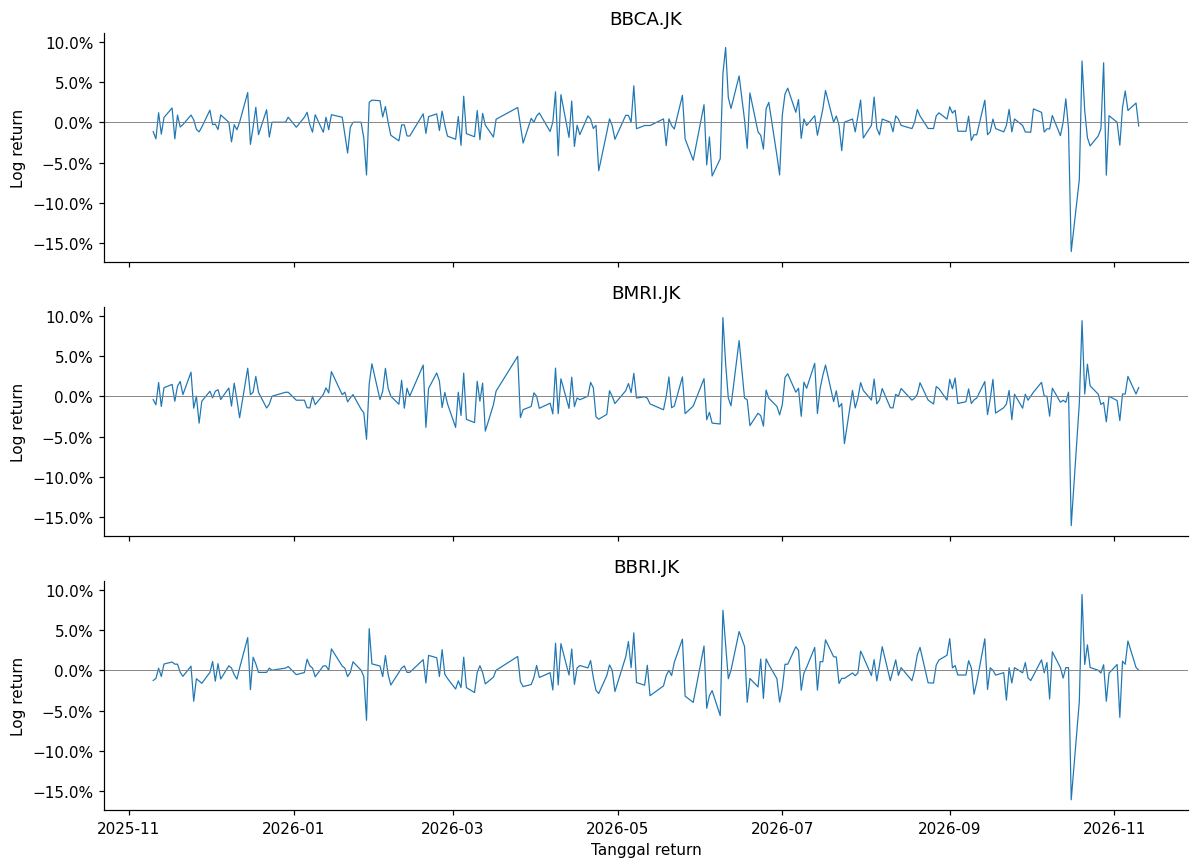

**Gambar 1.** Log return harian ketiga saham tanpa penyaringan; panel menggunakan skala vertikal yang sama.

In [3]:
return_grid = np.log(prices / prices.shift(1)).loc[RETURN_START:RETURN_END]
valid_intervals = return_grid.notna().all(axis=1)
returns = return_grid.loc[valid_intervals].copy()
if not np.isfinite(returns.to_numpy()).all() or len(returns) <= WINDOW:
    raise ValueError('Return tidak valid atau belum cukup untuk rolling window yang dipilih.')

interval_audit = pd.DataFrame(index=prices.index)
interval_audit['previous_date'] = prices.index.to_series().shift(1)
interval_audit['calendar_days'] = prices.index.to_series().diff().dt.days
interval_audit = interval_audit.loc[RETURN_START:RETURN_END]
interval_audit['return_valid'] = valid_intervals
interval_audit.to_csv(TABLE_DIR / 'audit_interval.csv', index_label='date')
returns.to_csv(PROCESSED_DIR / 'return_mentah.csv', index_label='date', float_format='%.17g')
quality.to_csv(TABLE_DIR / 'kualitas_harga.csv', index_label='ticker')

display(pd.Series({
    'jumlah_tanggal_harga': len(prices), 'tanggal_return_kandidat': len(return_grid),
    'return_sah': len(returns), 'interval_dikeluarkan': int((~valid_intervals).sum()),
    'tanggal_return_pertama': str(returns.index.min().date()),
    'tanggal_return_terakhir': str(returns.index.max().date()),
    'jumlah_prediksi_rolling': len(returns) - WINDOW,
}, name='hasil_pemeriksaan').to_frame())

fig, axes = plt.subplots(len(TICKERS), 1, figsize=(11, 8), sharex=True, sharey=True)
for ax, ticker in zip(axes, TICKERS):
    ax.plot(return_grid.index, return_grid[ticker], color='tab:blue', linewidth=0.8)
    ax.axhline(0, color='0.5', linewidth=0.6)
    ax.set(title=ticker, ylabel='Log return')
    ax.yaxis.set_major_formatter(PercentFormatter(1))
axes[-1].set_xlabel('Tanggal return')
fig.tight_layout()
save_figure(fig, 'gambar_1_return.png')
display(Markdown('**Gambar 1.** Log return harian ketiga saham tanpa penyaringan; '
                 'panel menggunakan skala vertikal yang sama.'))


## 2. Diagnosis distribusi dan ketergantungan waktu

Seluruh return yang lolos pemeriksaan kualitas data dipertahankan, termasuk nilai ekstrem. Tidak ada penghapusan berdasarkan z-score atau hasil uji normalitas. Sampel penuh dipakai untuk diagnosis retrospektif; estimasi rolling memakai seluruh 120 return sah sebelum tanggal prediksi.

Analisis penyaringan nilai ekstrem akan dikerjakan dalam notebook terpisah. Bagian ini hanya menjelaskan karakteristik data yang dipakai oleh alur utama.

### 2.1. Uji normalitas Lilliefors

$H_0$: return berasal dari distribusi normal dengan parameter yang diestimasi. Tolak $H_0$ jika p-value $<0{,}05$. Tidak menolak $H_0$ tidak membuktikan normalitas. Uji marginal tiap saham juga tidak membuktikan normalitas multivariat.

P-value yang berada pada batas tabel ditulis sebagai batas. Apa pun hasil uji, model normal tetap dijalankan sebagai asumsi replikasi, disertai pembahasan keterbatasannya.

,perlakuan,ticker,n,D,p_value_table,p_value_tampil,keputusan_5pct,sifat
0,tanpa_filter,BBCA.JK,240,0.106451,0.001,<= 0.001,Tolak H0,diagnosis seluruh return sah
1,tanpa_filter,BMRI.JK,240,0.099541,0.001,<= 0.001,Tolak H0,diagnosis seluruh return sah
2,tanpa_filter,BBRI.JK,240,0.098420,0.001,<= 0.001,Tolak H0,diagnosis seluruh return sah


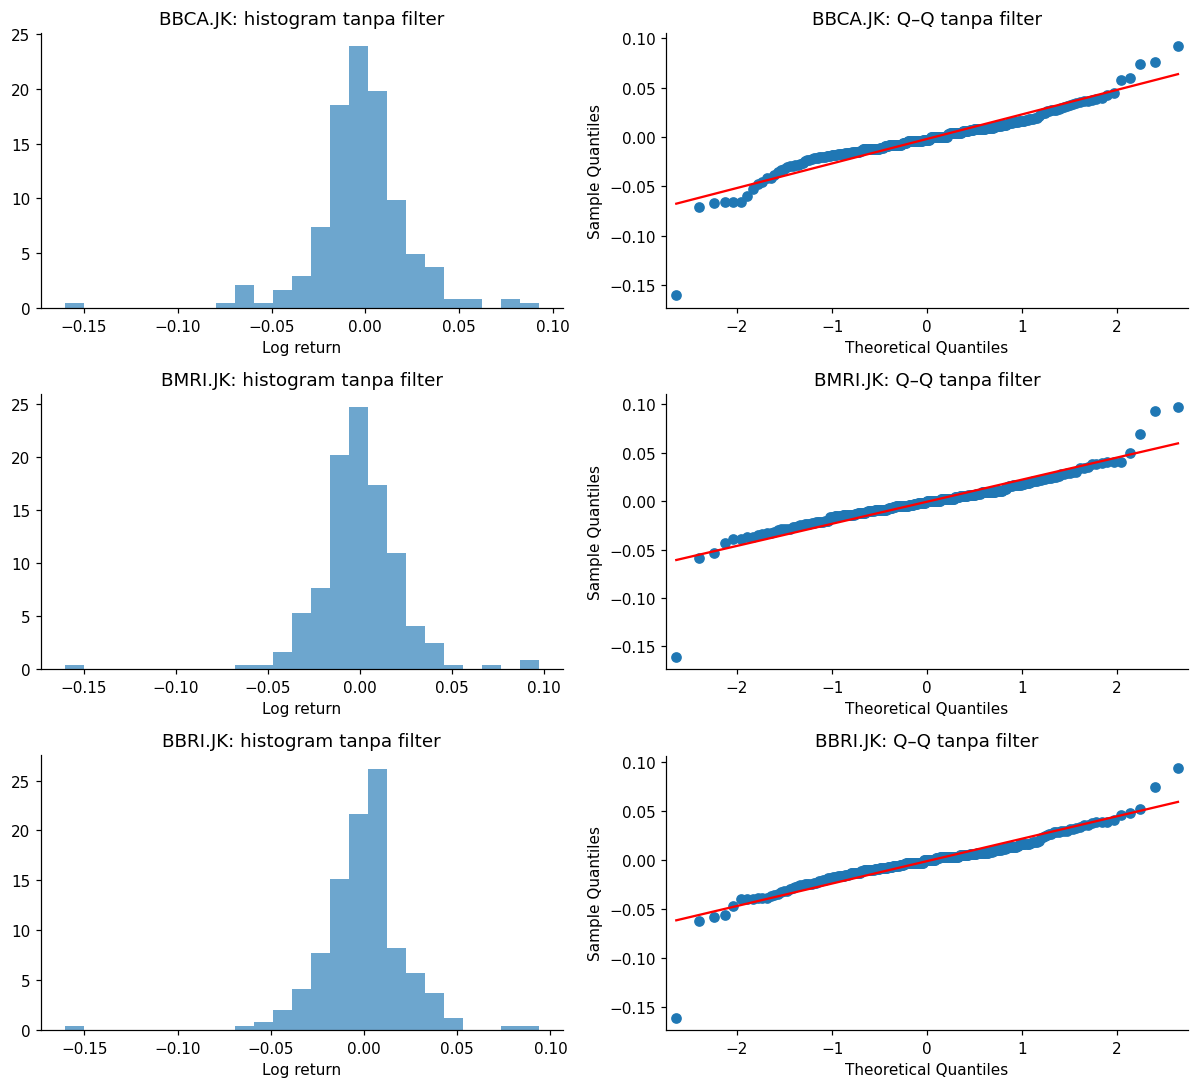

In [4]:
normality_rows = []
for ticker in TICKERS:
    statistic, p_value = lilliefors(returns[ticker], dist='norm', pvalmethod='table')
    p_label = (f'<= {p_value:.3f}' if p_value <= 0.001
               else f'>= {p_value:.3f}' if p_value >= 0.990 else f'{p_value:.6f}')
    normality_rows.append({
        'perlakuan': 'tanpa_filter', 'ticker': ticker, 'n': len(returns),
        'D': statistic, 'p_value_table': p_value, 'p_value_tampil': p_label,
        'keputusan_5pct': 'Tolak H0' if p_value < ALPHA else 'Tidak menolak H0',
        'sifat': 'diagnosis seluruh return sah',
    })
normality_table = pd.DataFrame(normality_rows)
normality_table.to_csv(TABLE_DIR / 'uji_normalitas.csv', index=False)
display(normality_table)

fig, axes = plt.subplots(len(TICKERS), 2, figsize=(11, 10))
for row, ticker in enumerate(TICKERS):
    axes[row, 0].hist(returns[ticker], bins=25, density=True, alpha=0.65)
    axes[row, 0].set(title=f'{ticker}: histogram tanpa filter', xlabel='Log return')
    qqplot(returns[ticker], line='s', ax=axes[row, 1])
    axes[row, 1].set_title(f'{ticker}: Q–Q tanpa filter')
fig.tight_layout()
save_figure(fig, '02_normalitas.png')

### 2.2. Ketergantungan waktu dan volatilitas

ACF return memeriksa hubungan antarwaktu; ACF kuadrat return membantu melihat pengelompokan volatilitas. Ini diagnosis grafis, bukan uji formal Ljung–Box. Model utama tidak memodelkan dinamika volatilitas seperti GARCH.

Gunakan grid tanggal asli penyedia dengan celah `NaN` tetap dipertahankan. Observasi yang hilang tidak dirapatkan seolah bersebelahan. Return ekstrem yang sah tetap ada pada diagnosis ini.

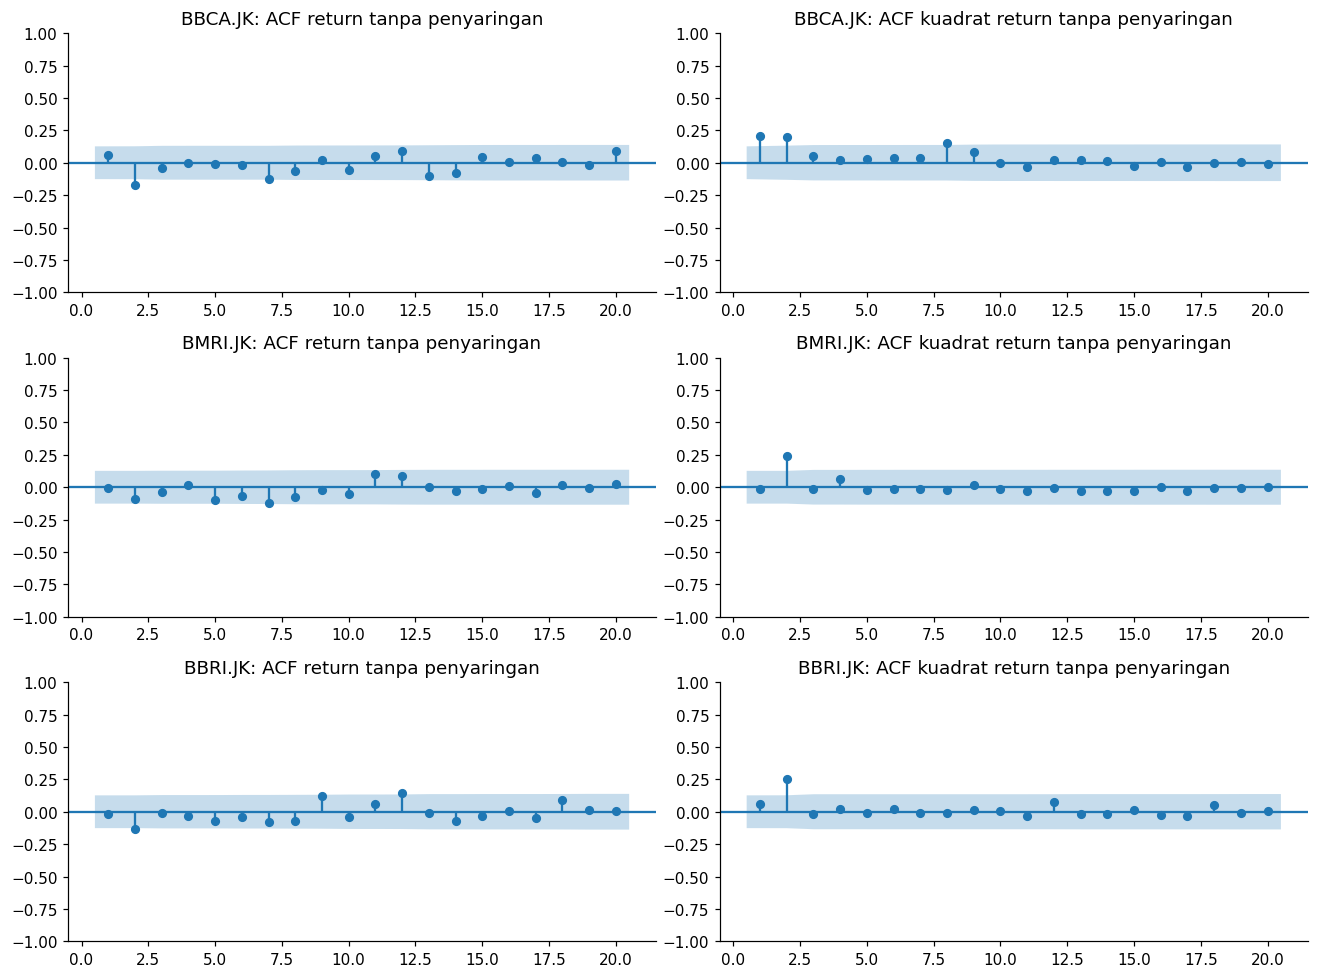

In [5]:
fig, axes = plt.subplots(len(TICKERS), 2, figsize=(12, 9))
lags = min(20, len(return_grid) // 4)
for row, ticker in enumerate(TICKERS):
    series = return_grid[ticker].where(valid_intervals)
    plot_acf(series, lags=lags, zero=False, missing='conservative', ax=axes[row, 0])
    plot_acf(series.pow(2), lags=lags, zero=False, missing='conservative', ax=axes[row, 1])
    axes[row, 0].set_title(f'{ticker}: ACF return tanpa penyaringan')
    axes[row, 1].set_title(f'{ticker}: ACF kuadrat return tanpa penyaringan')
fig.tight_layout()
save_figure(fig, '03_acf.png')

## 3. Mengestimasi mean, SD, kovarian, dan korelasi

Parameter dihitung dalam satuan harian. Kovarian sampel menggunakan penyebut $N-1$. Pemeriksaan nilai eigen dan kondisi matriks membantu mendeteksi masalah numerik sebelum GMV/Cholesky. Tidak ada regularisasi atau penghapusan aset otomatis.

In [6]:
def estimate_parameters(frame):
    values = frame.to_numpy(dtype=float)
    if len(frame) <= frame.shape[1] or not np.isfinite(values).all():
        raise ValueError('Sampel estimasi tidak cukup atau mengandung nilai tidak valid.')
    mu = values.mean(axis=0)
    covariance = np.cov(values, rowvar=False, ddof=1)
    if not np.allclose(covariance, covariance.T, rtol=1e-12, atol=1e-15):
        raise ValueError('Matriks kovarian tidak simetris.')
    eigenvalues = np.linalg.eigvalsh(covariance)
    if eigenvalues.min() <= 0:
        raise ValueError('Kovarian tidak positif definit; periksa data/model sebelum melanjutkan.')
    return {'mu': mu, 'cov': covariance, 'n': len(frame),
            'min_eigenvalue': float(eigenvalues.min()),
            'condition_number': float(np.linalg.cond(covariance))}


parameters = estimate_parameters(returns)
descriptive = returns.describe().T.assign(
    skewness=returns.skew(), excess_kurtosis=returns.kurt())
descriptive.index.name = 'ticker'
descriptive.insert(0, 'perlakuan', 'tanpa_filter')
descriptive.to_csv(TABLE_DIR / 'statistik_deskriptif.csv')
display(descriptive)
covariance = pd.DataFrame(parameters['cov'], index=TICKERS, columns=TICKERS)
correlation = returns.corr()
covariance.to_csv(TABLE_DIR / 'kovarian_tanpa_filter.csv')
correlation.to_csv(TABLE_DIR / 'korelasi_tanpa_filter.csv')
print('Eigen minimum:', parameters['min_eigenvalue'],
      '| condition number:', parameters['condition_number'])
display(covariance)
display(correlation)

,perlakuan,count,mean,std,min,25%,50%,75%,max,skewness,excess_kurtosis
ticker,,,,,,,,,,,
BBCA.JK,tanpa_filter,240.0,-0.001818,0.024911,-0.160343,-0.012435,-0.003022,0.009126,0.092659,-0.849864,7.871207
BMRI.JK,tanpa_filter,240.0,-0.000484,0.022870,-0.160452,-0.012092,0.000000,0.009858,0.097513,-0.741743,11.574275
BBRI.JK,tanpa_filter,240.0,-0.001021,0.022909,-0.160623,-0.010606,0.000000,0.008017,0.093878,-1.048971,10.625471


Eigen minimum: 9.840032786040898e-05 | condition number: 14.16449273184899


,BBCA.JK,BMRI.JK,BBRI.JK
BBCA.JK,0.000621,0.000401,0.000432
BMRI.JK,0.000401,0.000523,0.000421
BBRI.JK,0.000432,0.000421,0.000525


Ticker,BBCA.JK,BMRI.JK,BBRI.JK
Ticker,,,
BBCA.JK,1.000000,0.703307,0.756563
BMRI.JK,0.703307,1.000000,0.804494
BBRI.JK,0.756563,0.804494,1.000000


### Bahan artikel §3.1 — Statistik return dan diagnosis normalitas

Tabel 1 menyatukan statistik dan Lilliefors. Mean dan SD ditampilkan dalam persen;
variansi memakai return desimal kuadrat, dengan penyebut sampel $N-1$.
P-value pada batas tabel tetap ditulis sebagai batas. Q–Q dan ACF merupakan visual
pendukung; ACF yang ditampilkan adalah diagnosis grafis, bukan uji formal.

In [7]:
table_1 = pd.DataFrame({
    'Saham': TICKERS,
    'Mean (%)': returns.mean().reindex(TICKERS).to_numpy() * 100,
    'Variansi (desimal²)': returns.var(ddof=1).reindex(TICKERS).to_numpy(),
    'SD (%)': returns.std(ddof=1).reindex(TICKERS).to_numpy() * 100,
    'Skewness': returns.skew().reindex(TICKERS).to_numpy(),
    'Excess kurtosis': returns.kurt().reindex(TICKERS).to_numpy(),
}).merge(normality_table[['ticker', 'D', 'p_value_tampil']],
         left_on='Saham', right_on='ticker', validate='one_to_one').drop(columns='ticker')
table_1 = table_1.rename(columns={'D': 'Statistik Lilliefors', 'p_value_tampil': 'p-value'})
save_article_table(table_1, 'tabel_1_statistik_normalitas',
                   'Tabel 1. Statistik return harian dan diagnosis normalitas', {
                       'Mean (%)': '{:.4f}', 'Variansi (desimal²)': '{:.6e}',
                       'SD (%)': '{:.4f}', 'Skewness': '{:.4f}',
                       'Excess kurtosis': '{:.4f}', 'Statistik Lilliefors': '{:.4f}',
                   })
most_volatile = table_1.loc[table_1['SD (%)'].idxmax()]
rejected = normality_table.loc[normality_table['p_value_table'] < ALPHA, 'ticker'].tolist()
normality_result = ('H₀ normalitas ditolak untuk ' + ', '.join(rejected) if rejected
                    else 'H₀ normalitas tidak ditolak untuk ketiga saham')
display(Markdown(
    f"**Interpretasi §3.1.** Tabel 1 memakai {len(returns)} return sah per saham. "
    f"SD terbesar terdapat pada {most_volatile['Saham']} "
    f"({most_volatile['SD (%)']:.4f}% per hari). {normality_result} "
    f"pada taraf {ALPHA:.0%}. Skewness dan excess kurtosis dibaca bersama "
    "Q–Q plot untuk menilai asimetri dan ekor distribusi. Model normal tetap "
    "digunakan sebagai asumsi replikasi; hasil uji marginal tidak membuktikan "
    "normalitas multivariat. Gambar 1 mempertahankan seluruh fluktuasi ekstrem "
    "yang sah. Penyebab suatu lonjakan belum diidentifikasi melalui uji ini."
))

Saham,Mean (%),Variansi (desimal²),SD (%),Skewness,Excess kurtosis,Statistik Lilliefors,p-value
BBCA.JK,-0.1818,6.205771e-04,2.4911,-0.8499,7.8712,0.1065,<= 0.001
BMRI.JK,-0.0484,5.230290e-04,2.2870,-0.7417,11.5743,0.0995,<= 0.001
BBRI.JK,-0.1021,5.248322e-04,2.2909,-1.0490,10.6255,0.0984,<= 0.001


**Interpretasi §3.1.** Tabel 1 memakai 240 return sah per saham. SD terbesar terdapat pada BBCA.JK (2.4911% per hari). H₀ normalitas ditolak untuk BBCA.JK, BMRI.JK, BBRI.JK pada taraf 5%. Skewness dan excess kurtosis dibaca bersama Q–Q plot untuk menilai asimetri dan ekor distribusi. Model normal tetap digunakan sebagai asumsi replikasi; hasil uji marginal tidak membuktikan normalitas multivariat. Gambar 1 mempertahankan seluruh fluktuasi ekstrem yang sah. Penyebab suatu lonjakan belum diidentifikasi melalui uji ini.

## 4. Menentukan bobot GMV

$$w=\frac{\Sigma^{-1}\mathbf{1}}{\mathbf{1}'\Sigma^{-1}\mathbf{1}}.$$

Rumus yang disebut MVEP dalam paper menghasilkan **global minimum variance** tanpa target return dan tanpa kendala short selling. Secara numerik kita menyelesaikan sistem linear, tanpa menghitung invers secara eksplisit. Bobot negatif, bila ada, berarti posisi short. Eksposur bruto adalah $\sum_i |w_i|$.

Bobot pada tahap ini memakai sampel penuh. Pada rolling, bobot diestimasi ulang dari jendela pelatihan dan digunakan bersama oleh ketiga metode pada hari prediksi yang sama.

,tanpa_filter
BBCA.JK,0.2208
BMRI.JK,0.4265
BBRI.JK,0.3526


,perlakuan,mean_p_harian,sd_p_harian,eksposur_bruto
0,tanpa_filter,-0.000968,0.021452,1.0


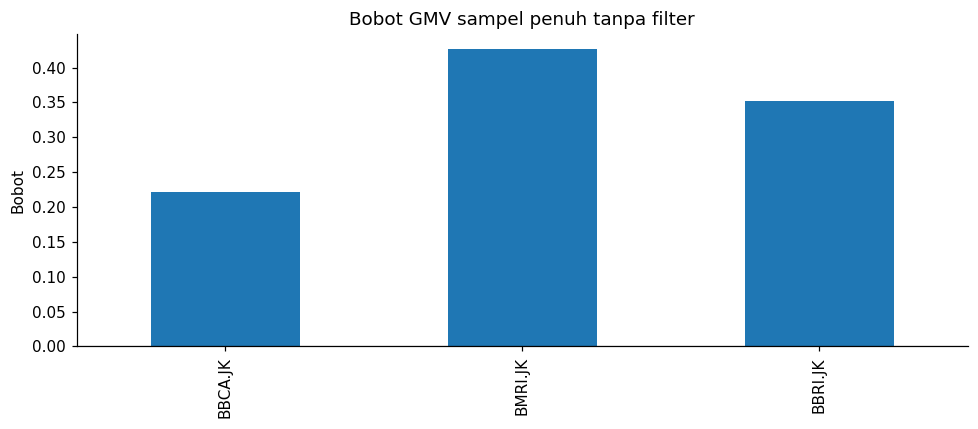

In [8]:
def fit_gmv(frame):
    model = estimate_parameters(frame)
    ones = np.ones(frame.shape[1])
    solution = np.linalg.solve(model['cov'], ones)
    weights = solution / (ones @ solution)
    if not np.isfinite(weights).all() or not np.isclose(weights.sum(), 1.0, atol=1e-10):
        raise ValueError('Bobot GMV tidak valid.')
    model.update({
        'weights': weights, 'chol': np.linalg.cholesky(model['cov']),
        'mu_p': float(weights @ model['mu']),
        'sigma_p': float(np.sqrt(weights @ model['cov'] @ weights)),
    })
    return model


model = fit_gmv(returns)
weights_table = pd.DataFrame({'tanpa_filter': model['weights']}, index=TICKERS)
weights_table.to_csv(TABLE_DIR / 'bobot_gmv.csv', index_label='ticker')
display(weights_table.style.format('{:.4f}'))
display(pd.DataFrame([{'perlakuan': 'tanpa_filter', 'mean_p_harian': model['mu_p'],
                       'sd_p_harian': model['sigma_p'],
                       'eksposur_bruto': np.abs(model['weights']).sum()}]))
fig, ax = plt.subplots(figsize=(9, 4))
weights_table.plot.bar(ax=ax, legend=False)
ax.axhline(0, color='black', linewidth=0.7)
ax.set(ylabel='Bobot', title='Bobot GMV sampel penuh tanpa filter')
fig.tight_layout()
save_figure(fig, '04_bobot.png')

### Bahan artikel §3.2 — Bobot dan karakteristik portofolio

Tabel 2 merangkum bobot dan parameter sampel penuh. Variansi portofolio
dihitung sebagai $w'\hat\Sigma w$; mean adalah estimasi expected return harian,
bukan janji return investasi. Satuan ditulis per baris agar variansi tidak
tertukar dengan persen return.

In [9]:
portfolio_variance = float(model['weights'] @ model['cov'] @ model['weights'])
table_2 = pd.DataFrame({
    'Komponen': [f'Bobot GMV {ticker}' for ticker in TICKERS] +
                 ['Expected return portofolio', 'Variansi portofolio', 'SD portofolio'],
    'Nilai': list(model['weights'] * 100) +
             [model['mu_p'] * 100, portfolio_variance, model['sigma_p'] * 100],
    'Satuan': ['%'] * len(TICKERS) + ['% per hari', 'desimal² per hari', '% per hari'],
})
save_article_table(table_2, 'tabel_2_portofolio',
                   'Tabel 2. Bobot GMV dan karakteristik portofolio sampel penuh',
                   {'Nilai': '{:.8g}'})
composition = ', '.join(f'{ticker} {weight:.4%}'
                        for ticker, weight in zip(TICKERS, model['weights']))
off_diagonal = correlation.to_numpy()[np.triu_indices(len(TICKERS), k=1)]
short_note = ('Terdapat posisi short pada hasil sampel penuh.'
              if (model['weights'] < 0).any() else
              'Seluruh bobot sampel penuh positif meskipun optimasi mengizinkan short selling.')
display(Markdown(
    f"**Interpretasi §3.2.** Komposisi pada Tabel 2 adalah {composition}. "
    f"{short_note} Mean portofolio {model['mu_p']:.4%} dan SD "
    f"{model['sigma_p']:.4%} per hari, dengan variansi {portfolio_variance:.6e}. "
    f"Korelasi antarsaham berkisar {off_diagonal.min():.4f}–{off_diagonal.max():.4f}. "
    "Bobot dipilih untuk meminimumkan variansi pada sampel estimasi, tanpa target "
    "return. Komposisi ini tidak membuktikan portofolio terbaik untuk seluruh "
    "kondisi pasar; bobot rolling dihitung ulang dari jendela pelatihan."
))

Komponen,Nilai,Satuan
Bobot GMV BBCA.JK,22.083145,%
Bobot GMV BMRI.JK,42.651905,%
Bobot GMV BBRI.JK,35.26495,%
Expected return portofolio,-0.096772514,% per hari
Variansi portofolio,0.00046020742,desimal² per hari
SD portofolio,2.1452446,% per hari


**Interpretasi §3.2.** Komposisi pada Tabel 2 adalah BBCA.JK 22.0831%, BMRI.JK 42.6519%, BBRI.JK 35.2650%. Seluruh bobot sampel penuh positif meskipun optimasi mengizinkan short selling. Mean portofolio -0.0968% dan SD 2.1452% per hari, dengan variansi 4.602074e-04. Korelasi antarsaham berkisar 0.7033–0.8045. Bobot dipilih untuk meminimumkan variansi pada sampel estimasi, tanpa target return. Komposisi ini tidak membuktikan portofolio terbaik untuk seluruh kondisi pasar; bobot rolling dihitung ulang dari jendela pelatihan.

## 5. Simulasi log return yang berkorelasi

$$r^{(m)}=\hat\mu+Lz^{(m)},\qquad LL'=\hat\Sigma,\quad z^{(m)}\sim N(0,I).$$

Dengan skenario sebagai baris, bentuk komputasinya `Z @ L.T + mu`. **10.000 skenario adalah 10.000 kemungkinan satu hari**, bukan 10.000 hari berturut-turut. Simulasi independen antarsaham akan membuang hubungan antaraset.

Aliran acak memakai `SeedSequence([SEED, tahap, 0, kunci])`. Angka `0` mempertahankan identitas aliran acak jalur tanpa filter dari run sebelumnya. Kode tahap: 1 ilustrasi, 2 estimasi penuh, 3 konvergensi, 4 rolling. Pada rolling, kuncinya tanggal `YYYYMMDD`; pada konvergensi, kuncinya jumlah skenario. Setiap pengulangan memakai child seed berbeda.

In [10]:
def make_seed(stage, key=0):
    return np.random.SeedSequence([SEED, stage, 0, key])

def simulate_asset_returns(model, n_scenarios, rng):
    z = rng.standard_normal((n_scenarios, len(model['mu'])))
    return z @ model['chol'].T + model['mu']

example_model = model
example_rng = np.random.default_rng(make_seed(1))
example_returns = simulate_asset_returns(example_model, M, example_rng)
mean_check = pd.DataFrame({'mean_input': example_model['mu'],
                            'mean_simulasi': example_returns.mean(axis=0)}, index=TICKERS)
cov_check = pd.DataFrame(np.cov(example_returns, rowvar=False, ddof=1), index=TICKERS, columns=TICKERS)
display(mean_check)
display(cov_check)
mean_check.to_csv(TABLE_DIR / 'cek_mean_skenario.csv', index_label='ticker')
cov_check.to_csv(TABLE_DIR / 'cek_kovarian_skenario.csv', index_label='ticker')
print('Jumlah skenario ilustrasi:', len(example_returns))

,mean_input,mean_simulasi
BBCA.JK,-0.001818,-0.001291
BMRI.JK,-0.000484,-0.000213
BBRI.JK,-0.001021,-0.000640


,BBCA.JK,BMRI.JK,BBRI.JK
BBCA.JK,0.000602,0.000389,0.000425
BMRI.JK,0.000389,0.000514,0.000414
BBRI.JK,0.000425,0.000414,0.000519


Jumlah skenario ilustrasi: 10000


## 6. Return dan loss portofolio

$$\tilde r_p^{(m)}=w'r^{(m)},\qquad \ell^{(m)}=-\tilde r_p^{(m)}.$$

Loss positif berarti rugi, sedangkan loss negatif berarti untung. Penjumlahan berbobot log return ini merupakan **pendekatan linear untuk horizon harian**, bukan agregasi return portofolio eksak. Semua metode dan loss aktual memakai definisi yang sama. Konversi rupiah juga merupakan pendekatan.

In [11]:
example_portfolio_returns = example_returns @ example_model['weights']
example_losses = -example_portfolio_returns
display(pd.Series(example_losses, name='loss_simulasi').describe().to_frame())

,loss_simulasi
count,10000.000000
mean,0.000601
std,0.021244
min,-0.088971
25%,-0.013402
50%,0.000653
75%,0.014556
max,0.080141


## 7. VaR pada tingkat kepercayaan 90%, 95%, dan 99%

$$\operatorname{VaR}_c=q_c(\ell)=-q_{1-c}(\tilde r_p).$$

Kita memakai kuantil sampel linear tipe 7, sama untuk MC dan historis. VaR 95% adalah ambang loss yang diperkirakan dilampaui dalam 5% kasus menurut model, bukan kerugian maksimum mutlak. Nilai negatif tidak dipaksa menjadi positif.

In [12]:
example_var = np.quantile(example_losses, LEVELS, method='linear')
display(pd.DataFrame({'confidence': LEVELS, 'VaR_desimal': example_var,
                       'VaR_persen': 100 * example_var,
                       'VaR_rupiah_pendekatan': V0 * example_var}))

,confidence,VaR_desimal,VaR_persen,VaR_rupiah_pendekatan
0,0.90,0.027702,2.770233,2.770233e+06
1,0.95,0.035558,3.555814,3.555814e+06
2,0.99,0.050178,5.017800,5.017800e+06


## 8. CVaR sebagai rata-rata ekor terburuk

Untuk model kontinu, $\operatorname{CVaR}_c=E[\ell\mid\ell\ge\operatorname{VaR}_c]$. Dengan $M=10.000$, ekor terburuk berisi 1.000, 500, dan 100 skenario pada level yang dipilih, tanpa ties.

Fungsi di bawah memakai pembobotan massa ekor tepat $h=N(1-c)$: jumlahkan $\lfloor h\rfloor$ loss terbesar, tambahkan pecahan observasi berikutnya jika perlu, lalu bagi $h$. Jika $h$ bulat dan loss kontinu, ini sama dengan rata-rata ekor pada rancangan utama. Cara ini juga menangani ukuran simulasi lain dan ties secara konsisten. CVaR dapat dilampaui oleh kerugian aktual.

,confidence,var,cvar,tail_count,tail_mass_n
0,0.90,0.027702,0.037986,1000,1000.0
1,0.95,0.035558,0.044678,500,500.0
2,0.99,0.050178,0.057483,100,100.0


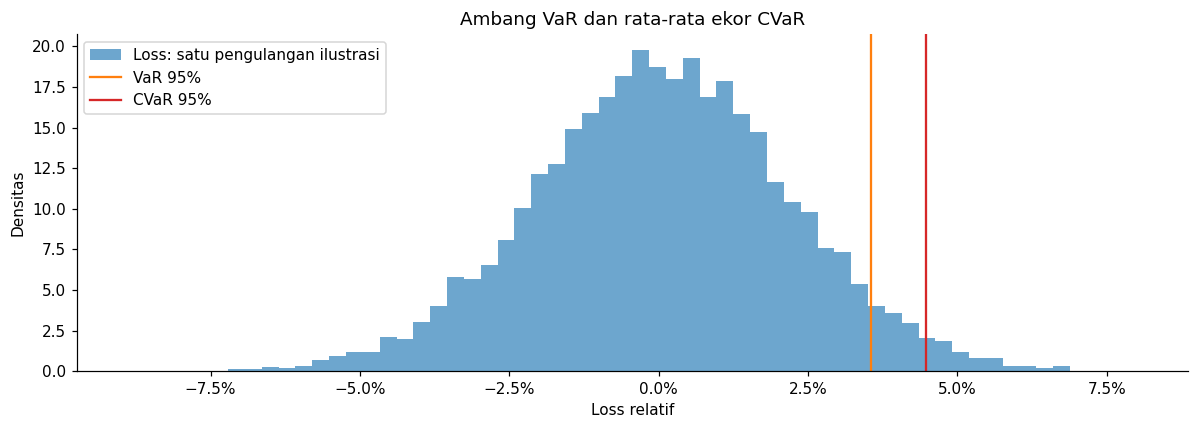

**Gambar 2.** Distribusi loss dari satu pengulangan ilustrasi dan penanda VaR/CVaR 95%. Estimasi utama pada Tabel 3 merupakan rata-rata 100 pengulangan; garis ilustrasi ini dapat berbeda sedikit.

In [13]:
def risk_from_losses(losses, levels=LEVELS):
    losses = np.asarray(losses, dtype=float)
    if losses.ndim != 1 or losses.size < 2 or not np.isfinite(losses).all():
        raise ValueError('Loss harus berupa vektor finite dengan minimal dua observasi.')
    quantiles = np.quantile(losses, levels, method='linear')
    descending = np.sort(losses)[::-1]
    cumulative = np.concatenate(([0.0], np.cumsum(descending)))
    rows = []
    for confidence, var in zip(levels, quantiles):
        h = len(losses) * (1 - confidence)
        if not 0 < h < len(losses):
            raise ValueError('Tingkat kepercayaan harus berada di antara 0 dan 1.')
        if np.isclose(h, round(h), atol=1e-10, rtol=0):
            h = float(round(h))
        j = int(np.floor(h))
        cvar = (cumulative[j] + (h - j) * descending[j]) / h
        rows.append({'confidence': float(confidence), 'var': float(var), 'cvar': float(cvar),
                     'tail_count': int(np.count_nonzero(losses >= var)), 'tail_mass_n': h})
    return pd.DataFrame(rows)

example_risk = risk_from_losses(example_losses)
display(example_risk)
fig, ax = plt.subplots(figsize=(11, 4))
ax.hist(example_losses, bins=60, density=True, alpha=0.65, label='Loss: satu pengulangan ilustrasi')
row95 = example_risk.iloc[1]
ax.axvline(row95['var'], color='tab:orange', label='VaR 95%')
ax.axvline(row95['cvar'], color='tab:red', label='CVaR 95%')
ax.xaxis.set_major_formatter(PercentFormatter(1))
ax.set(xlabel='Loss relatif', ylabel='Densitas', title='Ambang VaR dan rata-rata ekor CVaR')
ax.legend()
fig.tight_layout()
save_figure(fig, 'gambar_2_distribusi_loss.png')
display(Markdown('**Gambar 2.** Distribusi loss dari satu pengulangan ilustrasi dan '
                 'penanda VaR/CVaR 95%. Estimasi utama pada Tabel 3 merupakan '
                 'rata-rata 100 pengulangan; garis ilustrasi ini dapat berbeda sedikit.'))


## 9. Mengulang simulasi sebanyak 100 kali

Mean, kovarian, dan bobot tetap pada setiap sampel estimasi. Yang berubah hanya skenario acak. VaR/CVaR dihitung **per pengulangan**, kemudian dirata-ratakan. Menggabungkan seluruh skenario sebelum mengambil satu kuantil merupakan estimator berbeda.

Fungsi bersama ini dipakai untuk estimasi penuh, konvergensi, dan rolling. Hanya satu matriks skenario berada dalam memori pada satu waktu; hasil tiap pengulangan disimpan, bukan semua skenario sepanjang tahun.

In [14]:
def run_mc(model, n_scenarios, n_repeats, seed_sequence):
    if n_scenarios < 2 or n_repeats < 2:
        raise ValueError('MC memerlukan minimal dua skenario dan dua pengulangan untuk menghitung SD/SE.')
    repetitions = []
    for repeat, child_seed in enumerate(seed_sequence.spawn(n_repeats), start=1):
        asset_returns = simulate_asset_returns(model, n_scenarios, np.random.default_rng(child_seed))
        losses = -(asset_returns @ model['weights'])
        result = risk_from_losses(losses)
        result.insert(0, 'repeat', repeat)
        repetitions.append(result)
    repetitions = pd.concat(repetitions, ignore_index=True)
    summary = repetitions.groupby('confidence')[['var', 'cvar']].agg(['mean', 'std'])
    summary.columns = ['_'.join(parts) for parts in summary.columns]
    summary['var_se'] = summary['var_std'] / np.sqrt(n_repeats)
    summary['cvar_se'] = summary['cvar_std'] / np.sqrt(n_repeats)
    summary = summary.reset_index()
    if (summary['cvar_mean'] < summary['var_mean'] - 1e-12).any():
        raise ArithmeticError('CVaR lebih kecil dari VaR; periksa perhitungan.')
    if (np.diff(summary['var_mean']) < -1e-12).any() or (np.diff(summary['cvar_mean']) < -1e-12).any():
        raise ArithmeticError('Urutan risiko antar level tidak konsisten.')
    return repetitions, summary


started = time.perf_counter()
full_repetitions, full_summary = run_mc(model, M, K, make_seed(2))
full_repetitions = full_repetitions.assign(perlakuan='tanpa_filter')
full_summary = full_summary.assign(perlakuan='tanpa_filter', M=M, K=K, n_estimasi=model['n'])
print(f"Sampel penuh tanpa filter: {time.perf_counter() - started:.2f} detik")
full_repetitions.to_csv(TABLE_DIR / 'mc_pengulangan_sampel_penuh.csv', index=False)
full_summary.to_csv(TABLE_DIR / 'mc_ringkasan_sampel_penuh.csv', index=False)
display(full_summary)

Sampel penuh tanpa filter: 0.16 detik


,confidence,var_mean,var_std,cvar_mean,cvar_std,var_se,cvar_se,perlakuan,M,K,n_estimasi
0,0.90,0.028491,0.000382,0.038662,0.000425,0.000038,0.000043,tanpa_filter,10000,100,240
1,0.95,0.036309,0.000470,0.045263,0.000520,0.000047,0.000052,tanpa_filter,10000,100,240
2,0.99,0.050876,0.000742,0.058174,0.001017,0.000074,0.000102,tanpa_filter,10000,100,240


## 10. Rata-rata, SD, dan galat Monte Carlo

$$\bar\theta=K^{-1}\sum_k\hat\theta_k,\quad
s_{MC}=\sqrt{\frac{\sum_k(\hat\theta_k-\bar\theta)^2}{K-1}},\quad
SE_{MC}(\bar\theta)=s_{MC}/\sqrt K.$$

SD mengukur variasi antarpengulangan, sedangkan SE mengukur galat rata-rata simulasi **bersyarat pada parameter yang diestimasi**. Keduanya bukan seluruh ketidakpastian akibat terbatasnya data pasar. Kolom tampilan SE menggunakan **poin persentase**, sedangkan CSV utama menyimpan desimal.

In [15]:
full_display = full_summary[['perlakuan', 'confidence', 'var_mean', 'cvar_mean',
                              'var_std', 'cvar_std', 'var_se', 'cvar_se']].copy()
full_display = full_display.rename(columns={
    'var_mean': 'VaR_pct', 'cvar_mean': 'CVaR_pct', 'var_std': 'SD_VaR_pp',
    'cvar_std': 'SD_CVaR_pp', 'var_se': 'SE_mean_VaR_pp', 'cvar_se': 'SE_mean_CVaR_pp',
})
for column in full_display.columns[2:]:
    full_display[column] *= 100
display(full_display.style.format({column: '{:.6f}' for column in full_display.columns[2:]}))
full_display.to_csv(TABLE_DIR / 'risiko_persen_dan_se_pp.csv', index=False)

,perlakuan,confidence,VaR_pct,CVaR_pct,SD_VaR_pp,SD_CVaR_pp,SE_mean_VaR_pp,SE_mean_CVaR_pp
0,tanpa_filter,0.900000,2.849094,3.866170,0.038247,0.042547,0.003825,0.004255
1,tanpa_filter,0.950000,3.630941,4.526269,0.047044,0.051955,0.004704,0.005196
2,tanpa_filter,0.990000,5.087600,5.817390,0.074222,0.101693,0.007422,0.010169


### Bahan artikel §3.3 — Estimasi risiko Monte Carlo

Tabel 3 menampilkan rata-rata risiko dari 100 pengulangan. SE merupakan galat
rata-rata MC dalam **poin persentase (pp)**, bersyarat pada parameter estimasi.
SD antar-pengulangan tetap tersedia pada tabel rinci. Ilustrasi rupiah dihitung
dari estimasi utama, sedangkan Gambar 2 memakai satu pengulangan ilustrasi.

In [16]:
table_3 = pd.DataFrame({
    'Tingkat kepercayaan (%)': full_summary['confidence'] * 100,
    'VaR (%)': full_summary['var_mean'] * 100,
    'CVaR (%)': full_summary['cvar_mean'] * 100,
    'SE VaR (pp)': full_summary['var_se'] * 100,
    'SE CVaR (pp)': full_summary['cvar_se'] * 100,
})
save_article_table(table_3, 'tabel_3_risiko_mc',
                   'Tabel 3. Estimasi VaR dan CVaR Monte Carlo satu hari', {
                       'Tingkat kepercayaan (%)': '{:.0f}', 'VaR (%)': '{:.4f}',
                       'CVaR (%)': '{:.4f}', 'SE VaR (pp)': '{:.6f}',
                       'SE CVaR (pp)': '{:.6f}',
                   })
risk_95 = full_summary.loc[np.isclose(full_summary['confidence'], 0.95)].iloc[0]
display(Markdown(
    f"**Interpretasi §3.3.** Pada level 95%, Tabel 3 memberikan VaR "
    f"{risk_95['var_mean']:.4%} dan CVaR {risk_95['cvar_mean']:.4%}. "
    f"Untuk dana Rp{V0:,.0f}, nilainya sekitar Rp{V0 * risk_95['var_mean']:,.0f} "
    f"dan Rp{V0 * risk_95['cvar_mean']:,.0f}. VaR adalah ambang kerugian model, "
    "sedangkan CVaR adalah rata-rata loss pada ekor terburuk; keduanya dapat "
    "dilampaui oleh kerugian aktual. Tabel 3 memperlihatkan perubahan risiko "
    "menurut tingkat kepercayaan. SE kecil menunjukkan presisi simulasi "
    "bersyarat, tanpa mencakup ketidakpastian parameter atau kesalahan model. "
    "Konversi rupiah mengikuti pendekatan linear return portofolio harian."
))

Tingkat kepercayaan (%),VaR (%),CVaR (%),SE VaR (pp),SE CVaR (pp)
90,2.8491,3.8662,0.003825,0.004255
95,3.6309,4.5263,0.004704,0.005196
99,5.0876,5.8174,0.007422,0.010169


**Interpretasi §3.3.** Pada level 95%, Tabel 3 memberikan VaR 3.6309% dan CVaR 4.5263%. Untuk dana Rp100,000,000, nilainya sekitar Rp3,630,941 dan Rp4,526,269. VaR adalah ambang kerugian model, sedangkan CVaR adalah rata-rata loss pada ekor terburuk; keduanya dapat dilampaui oleh kerugian aktual. Tabel 3 memperlihatkan perubahan risiko menurut tingkat kepercayaan. SE kecil menunjukkan presisi simulasi bersyarat, tanpa mencakup ketidakpastian parameter atau kesalahan model. Konversi rupiah mengikuti pendekatan linear return portofolio harian.

### 10.1. Pembanding analitik normal dan VaR historis

$$\mu_p=w'\mu,\quad\sigma_p=\sqrt{w'\Sigma w},$$
$$\operatorname{VaR}_c^{normal}=-\mu_p+\sigma_p\Phi^{-1}(c),\qquad
\operatorname{CVaR}_c^{normal}=-\mu_p+\sigma_p\frac{\phi(\Phi^{-1}(c))}{1-c}.$$

MC dan parametrik memakai model probabilitas yang sama, sehingga seharusnya mendekat. Rasio selisih terhadap SE membantu pemeriksaan, tetapi bias kuantil/ekor pada $M$ terbatas tetap ada. VaR historis memakai kuantil loss dari return sampel dengan bobot yang sama; CVaR historis tidak menjadi pembanding utama.

In [17]:
def normal_risk(model, levels=LEVELS):
    z = norm.ppf(levels)
    return pd.DataFrame({
        'confidence': levels,
        'var_normal': -model['mu_p'] + model['sigma_p'] * z,
        'cvar_normal': -model['mu_p'] + model['sigma_p'] * norm.pdf(z) / (1 - levels),
    })


comparison_table = full_summary.merge(normal_risk(model), on='confidence', validate='one_to_one')
historical_loss = -(returns.to_numpy() @ model['weights'])
comparison_table['var_historical'] = np.quantile(historical_loss, LEVELS, method='linear')
for metric in ['var', 'cvar']:
    comparison_table[f'{metric}_difference'] = comparison_table[f'{metric}_mean'] - comparison_table[f'{metric}_normal']
    comparison_table[f'{metric}_difference_over_se'] = comparison_table[f'{metric}_difference'] / comparison_table[f'{metric}_se']
comparison_table.to_csv(TABLE_DIR / 'pembanding_analitik_historis.csv', index=False)
display(comparison_table[['perlakuan', 'confidence', 'var_mean', 'var_normal', 'var_historical',
                          'cvar_mean', 'cvar_normal', 'var_difference_over_se', 'cvar_difference_over_se']])

,perlakuan,confidence,var_mean,var_normal,var_historical,cvar_mean,cvar_normal,var_difference_over_se,cvar_difference_over_se
0,tanpa_filter,0.90,0.028491,0.028460,0.022988,0.038662,0.038616,0.805330,1.064379
1,tanpa_filter,0.95,0.036309,0.036254,0.029379,0.045263,0.045218,1.180858,0.861004
2,tanpa_filter,0.99,0.050876,0.050874,0.043394,0.058174,0.058143,0.032689,0.303027


### Bahan artikel §3.4 — Pembanding estimasi VaR

Monte Carlo tetap menjadi metode utama. Parametrik normal memeriksa hasil pada
model probabilitas yang sama; historis menjadi pembanding empiris. Semua nilai
pada Tabel 4 memakai bobot sampel penuh dan definisi loss yang identik.

In [18]:
table_4 = pd.DataFrame({
    'Tingkat kepercayaan (%)': comparison_table['confidence'] * 100,
    'VaR Monte Carlo (%)': comparison_table['var_mean'] * 100,
    'VaR Parametrik Normal (%)': comparison_table['var_normal'] * 100,
    'VaR Historis (%)': comparison_table['var_historical'] * 100,
})
save_article_table(table_4, 'tabel_4_perbandingan_var',
                   'Tabel 4. Perbandingan VaR sampel penuh', {
                       'Tingkat kepercayaan (%)': '{:.0f}',
                       **{column: '{:.4f}' for column in table_4.columns[1:]},
                   })
max_difference_pp = comparison_table['var_difference'].abs().max() * 100
comparison_95 = comparison_table.loc[np.isclose(comparison_table['confidence'], 0.95)].iloc[0]
display(Markdown(
    f"**Interpretasi §3.4.** Selisih absolut terbesar VaR MC terhadap analitik "
    f"pada Tabel 4 adalah {max_difference_pp:.6f} pp. Pada 95%, VaR historis "
    f"{comparison_95['var_historical']:.4%}, dibanding MC "
    f"{comparison_95['var_mean']:.4%}. Kedekatan MC dengan analitik diperiksa "
    "sebagai konsistensi perhitungan pada model normal linear yang sama. "
    "Kesesuaian model terhadap data pasar perlu dinilai melalui diagnosis "
    "distribusi dan backtesting. Perbedaan dari historis bersifat deskriptif "
    "dan tidak cukup untuk menyatakan satu metode paling akurat."
))

Tingkat kepercayaan (%),VaR Monte Carlo (%),VaR Parametrik Normal (%),VaR Historis (%)
90,2.8491,2.8460,2.2988
95,3.6309,3.6254,2.9379
99,5.0876,5.0874,4.3394


**Interpretasi §3.4.** Selisih absolut terbesar VaR MC terhadap analitik pada Tabel 4 adalah 0.005555 pp. Pada 95%, VaR historis 2.9379%, dibanding MC 3.6309%. Kedekatan MC dengan analitik diperiksa sebagai konsistensi perhitungan pada model normal linear yang sama. Kesesuaian model terhadap data pasar perlu dinilai melalui diagnosis distribusi dan backtesting. Perbedaan dari historis bersifat deskriptif dan tidak cukup untuk menyatakan satu metode paling akurat.

### 10.2. Konvergensi jumlah skenario — dapat lebih lama

Bandingkan $M=1.000$, $10.000$, dan $100.000$, masing-masing $K=100$, pada sampel penuh tanpa filter. Gunakan aliran acak independen dari hasil utama. Parameter tetap; yang bertambah adalah informasi simulasi, bukan jumlah hari pasar.

Grafik menampilkan selisih dari solusi analitik dengan rentang $\pm2SE_{MC}$. Ini ilustrasi galat simulasi, bukan interval kepercayaan seluruh risiko pasar. Menambah pengulangan tidak menghapus bias estimator pada $M$ terbatas.

Konvergensi selesai: M=1,000


Konvergensi selesai: M=10,000


Konvergensi selesai: M=100,000


,confidence,var_mean,var_std,cvar_mean,cvar_std,var_se,cvar_se,var_normal,cvar_normal,perlakuan,M,K
0,0.90,0.028456,0.001189,0.038540,0.001300,0.000119,0.000130,0.028460,0.038616,tanpa_filter,1000,100
1,0.95,0.036084,0.001444,0.045060,0.001595,0.000144,0.000159,0.036254,0.045218,tanpa_filter,1000,100
2,0.99,0.050394,0.002620,0.057804,0.003293,0.000262,0.000329,0.050874,0.058143,tanpa_filter,1000,100
3,0.90,0.028446,0.000385,0.038590,0.000403,0.000039,0.000040,0.028460,0.038616,tanpa_filter,10000,100
4,0.95,0.036214,0.000433,0.045188,0.000513,0.000043,0.000051,0.036254,0.045218,tanpa_filter,10000,100
5,0.99,0.050772,0.000828,0.058066,0.001012,0.000083,0.000101,0.050874,0.058143,tanpa_filter,10000,100
6,0.90,0.028458,0.000109,0.038616,0.000118,0.000011,0.000012,0.028460,0.038616,tanpa_filter,100000,100
7,0.95,0.036242,0.000128,0.045213,0.000153,0.000013,0.000015,0.036254,0.045218,tanpa_filter,100000,100
8,0.99,0.050875,0.000250,0.058148,0.000296,0.000025,0.000030,0.050874,0.058143,tanpa_filter,100000,100


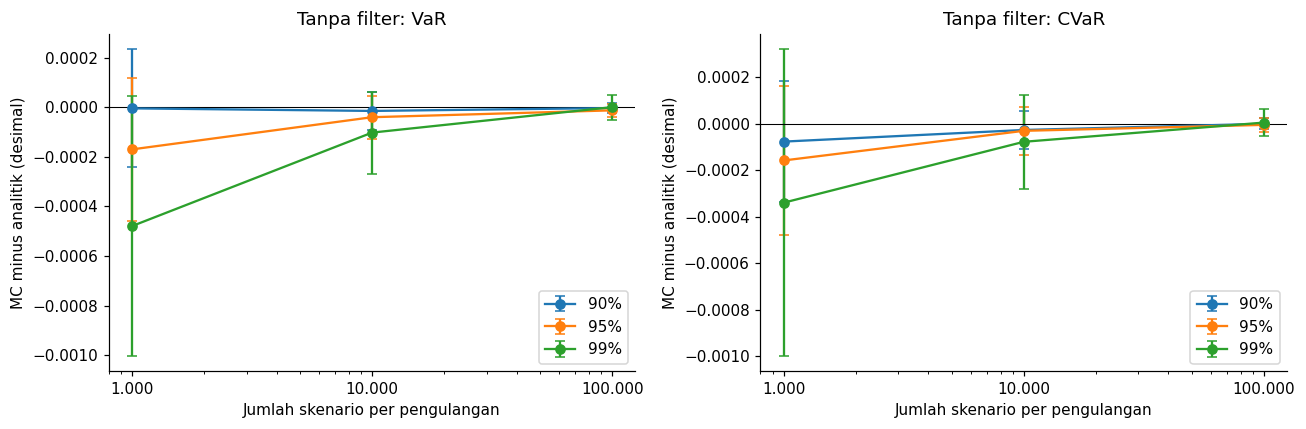

**Gambar 4.** Selisih MC terhadap solusi analitik dengan rentang ±2 SE MC. Penomoran mengikuti outline artikel; gambar ini mendukung pembahasan konvergensi.

In [19]:
convergence_table = None
if RUN_CONVERGENCE:
    convergence_rows = []
    for n_scenarios in CONVERGENCE_M:
        repetitions, summary = run_mc(model, n_scenarios, K, make_seed(3, n_scenarios))
        repetitions.assign(perlakuan='tanpa_filter', M=n_scenarios).to_csv(
            TABLE_DIR / f'konvergensi_pengulangan_tanpa_filter_{n_scenarios}.csv', index=False)
        summary = summary.merge(normal_risk(model), on='confidence', validate='one_to_one')
        convergence_rows.append(summary.assign(perlakuan='tanpa_filter', M=n_scenarios, K=K))
        print(f'Konvergensi selesai: M={n_scenarios:,}')
    convergence_table = pd.concat(convergence_rows, ignore_index=True)
    convergence_table.to_csv(TABLE_DIR / 'konvergensi.csv', index=False)
    display(convergence_table)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharex=True)
    for ax, metric in zip(axes, ['var', 'cvar']):
        for confidence in LEVELS:
            subset = convergence_table.loc[
                np.isclose(convergence_table['confidence'], confidence)].sort_values('M')
            ax.errorbar(subset['M'], subset[f'{metric}_mean'] - subset[f'{metric}_normal'],
                        yerr=2 * subset[f'{metric}_se'], marker='o', capsize=3,
                        label=f'{confidence:.0%}')
        ax.axhline(0, color='black', linewidth=0.7)
        ax.set(xscale='log', title=f"Tanpa filter: {dict(var='VaR', cvar='CVaR')[metric]}",
               ylabel='MC minus analitik (desimal)', xlabel='Jumlah skenario per pengulangan')
        ax.set_xlim(min(CONVERGENCE_M) * 0.8, max(CONVERGENCE_M) * 1.25)
        ax.set_xticks(CONVERGENCE_M, labels=[f'{value:,}'.replace(',', '.') for value in CONVERGENCE_M])
        ax.legend()
    fig.tight_layout()
    save_figure(fig, 'gambar_4_konvergensi.png')
    display(Markdown('**Gambar 4.** Selisih MC terhadap solusi analitik dengan rentang ±2 SE MC. Penomoran mengikuti outline artikel; gambar ini mendukung pembahasan konvergensi.'))
else:
    print('Konvergensi BELUM dijalankan. Set RUN_CONVERGENCE=True untuk melengkapinya.')

### Interpretasi konvergensi untuk §3.4

In [20]:
if convergence_table is not None:
    for confidence, group in convergence_table.groupby('confidence'):
        group = group.sort_values('M')
        first, last = group.iloc[0], group.iloc[-1]
        display(Markdown(
            f"Pada level **{confidence:.0%}**, ketika jumlah skenario berubah "
            f"dari {int(first['M']):,} ke {int(last['M']):,}, SE VaR berubah "
            f"dari {100 * first['var_se']:.6f} ke {100 * last['var_se']:.6f} pp; "
            f"SE CVaR dari {100 * first['cvar_se']:.6f} ke "
            f"{100 * last['cvar_se']:.6f} pp."
        ))
    display(Markdown(
        'Gambar 4 memperlihatkan galat terhadap solusi analitik. Selisih tiap titik '
        'dapat berfluktuasi dan tidak harus turun monoton. Penambahan skenario '
        'mengurangi galat simulasi, tanpa menambah hari observasi pasar atau '
        'menghilangkan ketidaksesuaian asumsi normal.'
    ))
else:
    display(Markdown('**Konvergensi belum dijalankan; interpretasi belum tersedia.**'))

Pada level **90%**, ketika jumlah skenario berubah dari 1,000 ke 100,000, SE VaR berubah dari 0.011886 ke 0.001088 pp; SE CVaR dari 0.013002 ke 0.001177 pp.

Pada level **95%**, ketika jumlah skenario berubah dari 1,000 ke 100,000, SE VaR berubah dari 0.014437 ke 0.001276 pp; SE CVaR dari 0.015948 ke 0.001533 pp.

Pada level **99%**, ketika jumlah skenario berubah dari 1,000 ke 100,000, SE VaR berubah dari 0.026200 ke 0.002500 pp; SE CVaR dari 0.032932 ke 0.002965 pp.

Gambar 4 memperlihatkan galat terhadap solusi analitik. Selisih tiap titik dapat berfluktuasi dan tidak harus turun monoton. Penambahan skenario mengurangi galat simulasi, tanpa menambah hari observasi pasar atau menghilangkan ketidaksesuaian asumsi normal.

## 11. Backtesting VaR

### 11.1. Uji Kupiec dan pemeriksaan dalam sampel

Pelanggaran terjadi jika **loss aktual lebih besar** daripada VaR. Untuk level $c$, peluang pelanggaran nominal $p=1-c$. Kupiec menguji frekuensi pelanggaran, menggunakan selisih log-likelihood dan pendekatan $\chi^2_1$. Fungsi `xlogy` menangani $0\log0=0$, termasuk nol atau seluruh observasi melanggar.

Hasil tidak menolak $H_0$ bukan bukti model valid secara menyeluruh. Uji ini tidak memvalidasi CVaR atau independensi pelanggaran. Hasil pada sampel pembentuk parameter di bawah dilabeli **dalam sampel**, bukan prediksi di luar sampel. Evaluasi memakai seluruh return mentah sah, termasuk return ekstrem.

In [21]:
def kupiec_test(n, x, confidence, alpha=ALPHA):
    if n <= 0 or not 0 <= x <= n or not 0 < confidence < 1:
        raise ValueError('Input Kupiec tidak valid.')
    p = 1 - confidence
    empirical_p = x / n
    log_null = xlogy(n - x, 1 - p) + xlogy(x, p)
    log_alternative = xlogy(n - x, 1 - empirical_p) + xlogy(x, empirical_p)
    lr = max(0.0, float(2 * (log_alternative - log_null)))
    p_value = float(chi2.sf(lr, df=1))
    return {'n': int(n), 'x': int(x), 'expected_x': n * p, 'failure_rate': empirical_p,
            'nominal_failure_rate': p, 'LR_POF': lr, 'p_value': p_value,
            'keputusan_5pct': 'Tolak H0' if p_value < alpha else 'Tidak menolak H0'}


actual_losses = -(returns.to_numpy() @ model['weights'])
in_sample_rows = []
for _, risk in comparison_table.iterrows():
    for method, column in [('Monte Carlo', 'var_mean'), ('Parametrik normal', 'var_normal'),
                           ('Historis', 'var_historical')]:
        result = kupiec_test(len(actual_losses), int(np.sum(actual_losses > risk[column])), risk['confidence'])
        in_sample_rows.append({'perlakuan': 'tanpa_filter', 'method': method,
                               'confidence': risk['confidence'], 'evaluasi': 'dalam_sampel', **result})
in_sample_table = pd.DataFrame(in_sample_rows)
in_sample_table.to_csv(TABLE_DIR / 'kupiec_dalam_sampel.csv', index=False)
display(in_sample_table)

,perlakuan,method,confidence,evaluasi,n,x,expected_x,failure_rate,nominal_failure_rate,LR_POF,p_value,keputusan_5pct
0,tanpa_filter,Monte Carlo,0.90,dalam_sampel,240,14,24.0,0.058333,0.10,5.364077,0.020556,Tolak H0
1,tanpa_filter,Parametrik normal,0.90,dalam_sampel,240,14,24.0,0.058333,0.10,5.364077,0.020556,Tolak H0
2,tanpa_filter,Historis,0.90,dalam_sampel,240,24,24.0,0.100000,0.10,0.000000,1.000000,Tidak menolak H0
3,tanpa_filter,Monte Carlo,0.95,dalam_sampel,240,8,12.0,0.033333,0.05,1.582327,0.208426,Tidak menolak H0
4,tanpa_filter,Parametrik normal,0.95,dalam_sampel,240,8,12.0,0.033333,0.05,1.582327,0.208426,Tidak menolak H0
5,tanpa_filter,Historis,0.95,dalam_sampel,240,12,12.0,0.050000,0.05,0.000000,1.000000,Tidak menolak H0
6,tanpa_filter,Monte Carlo,0.99,dalam_sampel,240,2,2.4,0.008333,0.01,0.071387,0.789328,Tidak menolak H0
7,tanpa_filter,Parametrik normal,0.99,dalam_sampel,240,2,2.4,0.008333,0.01,0.071387,0.789328,Tidak menolak H0
8,tanpa_filter,Historis,0.99,dalam_sampel,240,3,2.4,0.012500,0.01,0.140378,0.707906,Tidak menolak H0


### 11.2. Prediksi rolling di luar sampel — bagian utama yang lebih lama

Untuk tanggal $t$, ambil 120 return mentah sah sebelum $t$, gunakan semuanya untuk estimasi parameter/bobot, lalu hitung VaR ketiga metode. Loss aktual pada $t$ menggunakan bobot prediksi tersebut. Return ekstrem pada tanggal uji **tetap dinilai**. Ini pembaruan bobot harian; biaya transaksi, short selling, dan likuiditas tidak dimodelkan.

Jumlah hari uji adalah $T-120$, bukan jumlah simulasi. Checkpoint disimpan setelah satu tanggal prediksi selesai. Jika kernel terputus, jalankan lagi notebook dengan konfigurasi sama dan `RESUME_ROLLING=True`. Seed per tanggal membuat hasil yang dilanjutkan sama dengan eksekusi tanpa jeda. Satu prediksi yang belum selesai akan dihitung ulang.

Direktori checkpoint dibedakan oleh fingerprint data, konfigurasi, versi pustaka, dan sumber fungsi perhitungan yang sedang dimuat. Cache rusak/tidak sesuai menghentikan proses untuk diperiksa. Tidak ada tanggal prediksi yang dilewati diam-diam.

In [22]:
def predict_one_day(train, realized, date):
    model = fit_gmv(train)
    date_key = int(date.strftime('%Y%m%d'))
    repetitions, summary = run_mc(model, M, K, make_seed(4, date_key))
    analytic = normal_risk(model)
    historical_losses = -(train.to_numpy() @ model['weights'])
    historical_var = np.quantile(historical_losses, LEVELS, method='linear')
    realized_loss = float(-(realized.to_numpy() @ model['weights']))
    weight_record = {f'w_{ticker}': float(weight) for ticker, weight in zip(TICKERS, model['weights'])}
    common = {'date': date.strftime('%Y-%m-%d'), 'perlakuan': 'tanpa_filter',
              'train_start': train.index.min().strftime('%Y-%m-%d'),
              'train_end': train.index.max().strftime('%Y-%m-%d'),
              'n_window': len(train), 'n_fit': len(train),
              'n_removed': 0, 'loss': realized_loss,
              'gross_exposure': float(np.abs(model['weights']).sum()), **weight_record}
    predictions = []
    for position, confidence in enumerate(LEVELS):
        mc = summary.iloc[position]
        normal = analytic.iloc[position]
        estimates = [
            ('Monte Carlo', mc['var_mean'], mc['cvar_mean'], mc['var_se'], mc['cvar_se']),
            ('Parametrik normal', normal['var_normal'], normal['cvar_normal'], None, None),
            ('Historis', historical_var[position], None, None, None),
        ]
        for method, var, cvar, var_se, cvar_se in estimates:
            predictions.append({**common, 'confidence': float(confidence), 'method': method,
                                'var': float(var), 'cvar': None if cvar is None else float(cvar),
                                'mc_var_se': None if var_se is None else float(var_se),
                                'mc_cvar_se': None if cvar_se is None else float(cvar_se),
                                'breach': int(realized_loss > var)})
    return {'predictions': predictions, 'repetitions': repetitions.to_dict(orient='records'),
            'parameters': {'mu': model['mu'].tolist(), 'cov': model['cov'].tolist(),
                           'weights': model['weights'].tolist(),
                           'condition_number': model['condition_number']}}

### Penyimpanan hasil per tanggal

Fungsi berikut mengerjakan atau membaca kembali satu checkpoint tanggal prediksi. Parameter dan hasil per pengulangan ikut disimpan agar setiap prediksi dapat ditelusuri. Kegagalan perhitungan menghentikan proses pada tanggal terkait; checkpoint yang sudah lengkap tetap tersedia.

In [23]:
def rolling_backtest(data, checkpoint_folder, run_id):
    prediction_rows, repetition_rows = [], []
    n_dates = len(data) - WINDOW
    started = time.perf_counter()
    for position in range(WINDOW, len(data)):
        date = data.index[position]
        train = data.iloc[position - WINDOW:position]
        checkpoint = checkpoint_folder / f'{date:%Y%m%d}.json'
        if checkpoint.exists() and RESUME_ROLLING:
            payload = json.loads(checkpoint.read_text(encoding='utf-8'))
            if (payload['run_id'] != run_id or payload['date'] != date.strftime('%Y-%m-%d')
                    or payload['perlakuan'] != 'tanpa_filter'):
                raise ValueError(f'Identitas checkpoint tidak cocok: {checkpoint.name}')
            result = payload['result']
            if len(result['predictions']) != 3 * len(LEVELS) or len(result['repetitions']) != K * len(LEVELS):
                raise ValueError(f'Checkpoint tidak lengkap: {checkpoint.name}')
        else:
            result = predict_one_day(train, data.iloc[position], date)
            payload = {'run_id': run_id, 'date': date.strftime('%Y-%m-%d'),
                       'perlakuan': 'tanpa_filter', 'result': result}
            temporary = checkpoint.with_suffix('.tmp')
            temporary.write_text(json.dumps(payload, allow_nan=False), encoding='utf-8')
            temporary.replace(checkpoint)
        prediction_rows.extend(result['predictions'])
        repetition_rows.extend({**row, 'date': date.strftime('%Y-%m-%d'), 'perlakuan': 'tanpa_filter'}
                               for row in result['repetitions'])
        completed = position - WINDOW + 1
        if completed == 1 or completed % 10 == 0 or completed == n_dates:
            elapsed = time.perf_counter() - started
            print(f'{completed}/{n_dates} tanggal selesai | {date:%Y-%m-%d} | {elapsed:.1f} detik')
    predictions = pd.DataFrame(prediction_rows)
    predictions['date'] = pd.to_datetime(predictions['date'])
    repetitions = pd.DataFrame(repetition_rows)
    return predictions, repetitions

### Menjalankan rolling

Sel ini menjalankan seluruh tanggal uji dengan konfigurasi penelitian. Kemajuan ditampilkan setiap sepuluh tanggal. Hasil gabungan baru diekspor setelah seluruh tanggal selesai; jika terputus, jalankan kembali untuk memakai checkpoint yang sudah ada.

In [24]:
rolling_predictions = None
rolling_repetitions = None
rolling_run_id = None
if RUN_ROLLING:
    numerical_functions = [estimate_parameters, fit_gmv, make_seed,
                           simulate_asset_returns, risk_from_losses, run_mc, normal_risk,
                           predict_one_day, rolling_backtest]
    implementation = '\n'.join(inspect.getsource(function) for function in numerical_functions)
    rolling_config = {'tickers': TICKERS, 'levels': LEVELS.tolist(), 'window': WINDOW,
                      'M': M, 'K': K, 'seed': SEED, 'seed_stream_id': 0,
                      'perlakuan': 'tanpa_filter', 'quantile': 'linear_type7',
                      'loss': 'negative_weighted_log_return', 'versions': VERSIONS}
    data_digest = hashlib.sha256(pd.util.hash_pandas_object(returns, index=True).values.tobytes()).hexdigest()
    run_spec = {'config': rolling_config, 'data_sha256': data_digest,
                'implementation_sha256': hashlib.sha256(implementation.encode()).hexdigest()}
    rolling_run_id = hashlib.sha256(json.dumps(run_spec, sort_keys=True).encode()).hexdigest()[:20]
    run_folder = CHECKPOINT_DIR / rolling_run_id
    run_folder.mkdir(exist_ok=True)
    (run_folder / 'run_spec.json').write_text(json.dumps(run_spec, indent=2), encoding='utf-8')
    workload = (len(returns) - WINDOW) * M * K
    print(f'Run ID: {rolling_run_id} | total {workload:,} skenario aset bersama untuk seluruh prediksi.')
    rolling_predictions, rolling_repetitions = rolling_backtest(returns, run_folder, rolling_run_id)
    rolling_predictions.to_csv(TABLE_DIR / 'rolling_prediksi.csv', index=False)
    rolling_repetitions.to_csv(TABLE_DIR / 'rolling_mc_pengulangan.csv', index=False)
    rolling_weights = rolling_predictions.drop_duplicates('date')[
        ['date', 'perlakuan', 'train_start', 'train_end', 'n_window', 'n_fit', 'n_removed',
         'gross_exposure'] + [f'w_{ticker}' for ticker in TICKERS]]
    rolling_weights.to_csv(TABLE_DIR / 'rolling_bobot_estimasi.csv', index=False)
    display(rolling_predictions.head(9))
else:
    print('Rolling BELUM dijalankan. Set RUN_ROLLING=True untuk evaluasi di luar sampel.')

Run ID: 737743396df70c49b626 | total 120,000,000 skenario aset bersama untuk seluruh prediksi.
1/120 tanggal selesai | 2026-05-19 | 0.0 detik
10/120 tanggal selesai | 2026-06-04 | 0.0 detik
20/120 tanggal selesai | 2026-06-19 | 0.1 detik
30/120 tanggal selesai | 2026-07-03 | 0.1 detik
40/120 tanggal selesai | 2026-07-17 | 0.1 detik
50/120 tanggal selesai | 2026-07-31 | 0.1 detik
60/120 tanggal selesai | 2026-08-14 | 0.2 detik


70/120 tanggal selesai | 2026-09-01 | 0.2 detik
80/120 tanggal selesai | 2026-09-15 | 0.2 detik
90/120 tanggal selesai | 2026-09-29 | 0.3 detik
100/120 tanggal selesai | 2026-10-13 | 0.3 detik
110/120 tanggal selesai | 2026-10-27 | 0.3 detik
120/120 tanggal selesai | 2026-11-10 | 0.3 detik


,date,perlakuan,train_start,train_end,n_window,n_fit,n_removed,loss,gross_exposure,w_BBCA.JK,w_BMRI.JK,w_BBRI.JK,confidence,method,var,cvar,mc_var_se,mc_cvar_se,breach
0,2026-05-19,tanpa_filter,2025-11-10,2026-05-18,120,120,0,0.012389,1.0,0.327034,0.229302,0.443663,0.90,Monte Carlo,0.021236,0.028514,0.000028,0.000030,0
1,2026-05-19,tanpa_filter,2025-11-10,2026-05-18,120,120,0,0.012389,1.0,0.327034,0.229302,0.443663,0.90,Parametrik normal,0.021238,0.028536,NaN,NaN,0
2,2026-05-19,tanpa_filter,2025-11-10,2026-05-18,120,120,0,0.012389,1.0,0.327034,0.229302,0.443663,0.90,Historis,0.019246,NaN,NaN,NaN,0
3,2026-05-19,tanpa_filter,2025-11-10,2026-05-18,120,120,0,0.012389,1.0,0.327034,0.229302,0.443663,0.95,Monte Carlo,0.026821,0.033245,0.000034,0.000038,0
4,2026-05-19,tanpa_filter,2025-11-10,2026-05-18,120,120,0,0.012389,1.0,0.327034,0.229302,0.443663,0.95,Parametrik normal,0.026838,0.033279,NaN,NaN,0
5,2026-05-19,tanpa_filter,2025-11-10,2026-05-18,120,120,0,0.012389,1.0,0.327034,0.229302,0.443663,0.95,Historis,0.021399,NaN,NaN,NaN,0
6,2026-05-19,tanpa_filter,2025-11-10,2026-05-18,120,120,0,0.012389,1.0,0.327034,0.229302,0.443663,0.99,Monte Carlo,0.037239,0.042453,0.000056,0.000072,0
7,2026-05-19,tanpa_filter,2025-11-10,2026-05-18,120,120,0,0.012389,1.0,0.327034,0.229302,0.443663,0.99,Parametrik normal,0.037343,0.042566,NaN,NaN,0
8,2026-05-19,tanpa_filter,2025-11-10,2026-05-18,120,120,0,0.012389,1.0,0.327034,0.229302,0.443663,0.99,Historis,0.036659,NaN,NaN,NaN,0


### 11.3. Tabel Kupiec di luar sampel dan grafik pelanggaran

Laporkan jumlah hari uji $n$, jumlah pelanggaran $x$, harapan $n(1-c)$, proporsi pelanggaran, statistik LR, dan p-value. Pada level 99% dengan sekitar 120 hari uji, harapan pelanggaran hanya sekitar 1,2 sehingga bukti statistik terbatas.

Ketiga metode memakai seluruh return sah pada jendela pelatihan yang sama, serta tanggal evaluasi, bobot, dan loss aktual yang identik. P-value terbesar tidak otomatis berarti metode terbaik. Kupiec mengasumsikan model acuan Bernoulli independen dan tidak memeriksa pengelompokan pelanggaran.

,perlakuan,method,confidence,evaluasi,n,x,expected_x,failure_rate,nominal_failure_rate,LR_POF,p_value,keputusan_5pct
0,tanpa_filter,Historis,0.900000,di_luar_sampel,120,16,12.000000,0.1333,0.100000,1.355838,0.24426,Tidak menolak H0
1,tanpa_filter,Historis,0.950000,di_luar_sampel,120,10,6.000000,0.0833,0.050000,2.358534,0.124599,Tidak menolak H0
2,tanpa_filter,Historis,0.990000,di_luar_sampel,120,3,1.200000,0.0250,0.010000,1.925156,0.165289,Tidak menolak H0
3,tanpa_filter,Monte Carlo,0.900000,di_luar_sampel,120,13,12.000000,0.1083,0.100000,0.090398,0.763671,Tidak menolak H0
4,tanpa_filter,Monte Carlo,0.950000,di_luar_sampel,120,7,6.000000,0.0583,0.050000,0.166907,0.682875,Tidak menolak H0
5,tanpa_filter,Monte Carlo,0.990000,di_luar_sampel,120,4,1.200000,0.0333,0.010000,4.098300,0.0429263,Tolak H0
6,tanpa_filter,Parametrik normal,0.900000,di_luar_sampel,120,13,12.000000,0.1083,0.100000,0.090398,0.763671,Tidak menolak H0
7,tanpa_filter,Parametrik normal,0.950000,di_luar_sampel,120,7,6.000000,0.0583,0.050000,0.166907,0.682875,Tidak menolak H0
8,tanpa_filter,Parametrik normal,0.990000,di_luar_sampel,120,4,1.200000,0.0333,0.010000,4.098300,0.0429263,Tolak H0


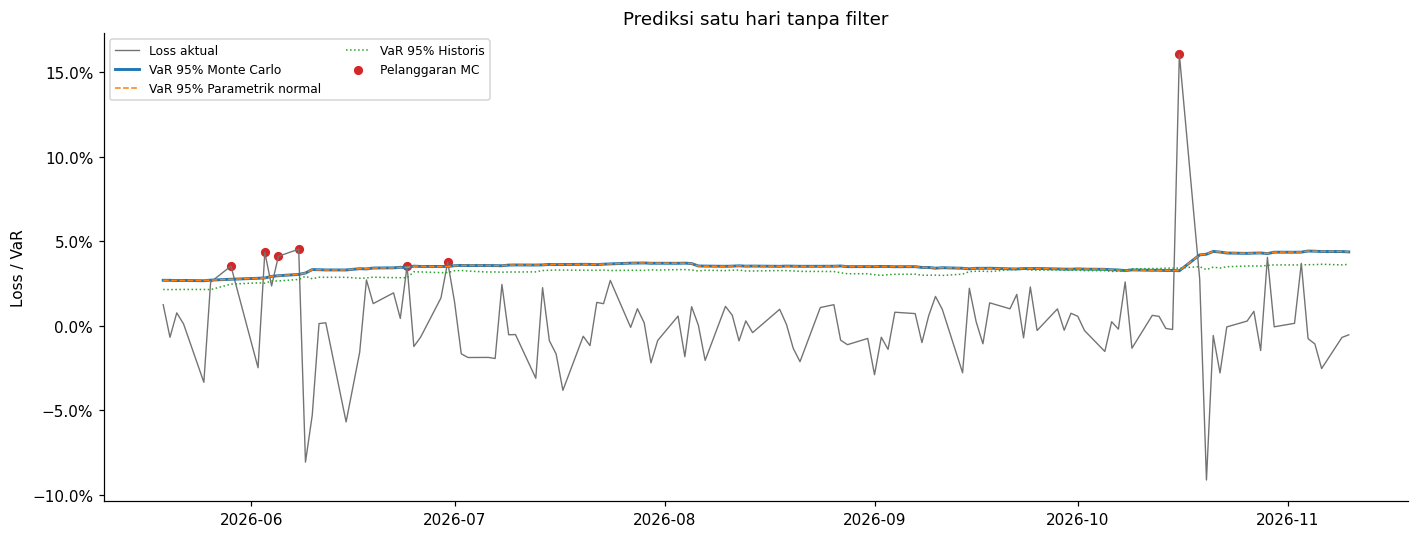

**Gambar 3.** Loss aktual dan prediksi VaR rolling 95%; titik merah menandai pelanggaran Monte Carlo.

In [25]:
rolling_kupiec = None
if rolling_predictions is not None:
    expected_dates = pd.DatetimeIndex(returns.index[WINDOW:])
    rows = []
    for (treatment, method, confidence), group in rolling_predictions.groupby(['perlakuan', 'method', 'confidence']):
        group = group.sort_values('date')
        if not pd.DatetimeIndex(group['date']).equals(expected_dates):
            raise AssertionError('Tanggal evaluasi tidak sama dengan seluruh tanggal prediksi yang diharapkan.')
        result = kupiec_test(len(group), int(group['breach'].sum()), confidence)
        rows.append({'perlakuan': treatment, 'method': method, 'confidence': confidence,
                     'evaluasi': 'di_luar_sampel', **result})
    rolling_kupiec = pd.DataFrame(rows)
    rolling_kupiec.to_csv(TABLE_DIR / 'kupiec_di_luar_sampel.csv', index=False)
    display(rolling_kupiec.style.format({'p_value': '{:.6g}', 'failure_rate': '{:.4f}'}))


    fig, ax = plt.subplots(figsize=(13, 5))
    subset = rolling_predictions.loc[np.isclose(rolling_predictions['confidence'], 0.95)]
    actual = subset.loc[subset['method'] == 'Monte Carlo'].sort_values('date')
    ax.plot(actual['date'], actual['loss'], color='0.45', linewidth=0.9, label='Loss aktual')
    for method, color, style, width in [
            ('Monte Carlo', 'tab:blue', '-', 1.9),
            ('Parametrik normal', 'tab:orange', '--', 1.0),
            ('Historis', 'tab:green', ':', 1.0)]:
        group = subset.loc[subset['method'] == method].sort_values('date')
        ax.plot(group['date'], group['var'], color=color, linestyle=style,
                linewidth=width, label=f'VaR 95% {method}')
    failures = actual.loc[actual['breach'] == 1]
    ax.scatter(failures['date'], failures['loss'], color='tab:red', s=25, label='Pelanggaran MC')
    ax.set(title='Prediksi satu hari tanpa filter', ylabel='Loss / VaR')
    ax.yaxis.set_major_formatter(PercentFormatter(1))
    ax.legend(fontsize=8, ncol=2)
    fig.tight_layout()
    save_figure(fig, 'gambar_3_rolling_var95.png')
    display(Markdown('**Gambar 3.** Loss aktual dan prediksi VaR rolling 95%; titik merah menandai pelanggaran Monte Carlo.'))
else:
    print('Tabel Kupiec di luar sampel belum tersedia; tidak diganti dengan hasil dalam sampel.')

### Bahan artikel §3.5 — Evaluasi rolling di luar sampel

Tabel 5 hanya memakai hasil di luar sampel. Monte Carlo ditampilkan terlebih dahulu,
diikuti kedua pembanding. Failure rate ditampilkan sebagai persen, p-value tidak
dibulatkan menjadi nol, dan keputusan mengikuti taraf signifikansi konfigurasi.

In [26]:
table_5 = None
if rolling_kupiec is not None:
    method_order = {'Monte Carlo': 0, 'Parametrik normal': 1, 'Historis': 2}
    ordered = (rolling_kupiec.assign(urutan=rolling_kupiec['method'].map(method_order))
               .sort_values(['urutan', 'confidence']))
    table_5 = ordered[['method', 'confidence', 'n', 'x', 'expected_x',
                       'failure_rate', 'LR_POF', 'p_value', 'keputusan_5pct']].copy()
    table_5['confidence'] *= 100
    table_5['failure_rate'] *= 100
    table_5 = table_5.rename(columns={
        'method': 'Metode', 'confidence': 'Tingkat kepercayaan (%)',
        'n': 'Jumlah uji (n)', 'x': 'Pelanggaran (x)',
        'expected_x': 'Ekspektasi pelanggaran', 'failure_rate': 'Failure rate (%)',
        'LR_POF': 'LR Kupiec', 'p_value': 'p-value', 'keputusan_5pct': 'Keputusan',
    })
    save_article_table(table_5, 'tabel_5_backtesting_rolling',
                       'Tabel 5. Backtesting VaR rolling di luar sampel', {
                           'Tingkat kepercayaan (%)': '{:.0f}', 'Jumlah uji (n)': '{:.0f}',
                           'Pelanggaran (x)': '{:.0f}', 'Ekspektasi pelanggaran': '{:.1f}',
                           'Failure rate (%)': '{:.4f}', 'LR Kupiec': '{:.6f}',
                           'p-value': '{:.6g}',
                       })
    for _, row in ordered.loc[ordered['method'] == 'Monte Carlo'].iterrows():
        display(Markdown(
            f"**Monte Carlo {row['confidence']:.0%}:** {int(row['x'])} pelanggaran "
            f"dari {int(row['n'])} hari, harapan {row['expected_x']:.1f}, "
            f"failure rate {row['failure_rate']:.4%}, "
            f"p-value {row['p_value']:.6g}: **{row['keputusan_5pct']}**."
        ))
    display(Markdown(
        '**Interpretasi §3.5.** Tabel 5 mengevaluasi cakupan VaR dengan bobot dan '
        'tanggal uji yang sama antarmetode. Gambar 3 menunjukkan waktu pelanggaran '
        'MC pada 95%. Tidak menolak H₀ belum membuktikan model valid secara '
        'menyeluruh. Kupiec tidak menguji besar kerugian ekor, independensi '
        'pelanggaran, atau validitas CVaR. Pada 99%, sedikitnya pelanggaran yang '
        'diharapkan membatasi kekuatan evaluasi dan ketepatan pendekatan asimtotik. '
        'P-value terbesar tidak otomatis menentukan metode terbaik.'
    ))
else:
    display(Markdown('**Tabel 5 belum tersedia: jalankan evaluasi rolling terlebih dahulu.**'))

Metode,Tingkat kepercayaan (%),Jumlah uji (n),Pelanggaran (x),Ekspektasi pelanggaran,Failure rate (%),LR Kupiec,p-value,Keputusan
Monte Carlo,90,120,13,12.0,10.8333,0.090398,0.763671,Tidak menolak H0
Monte Carlo,95,120,7,6.0,5.8333,0.166907,0.682875,Tidak menolak H0
Monte Carlo,99,120,4,1.2,3.3333,4.098300,0.0429263,Tolak H0
Parametrik normal,90,120,13,12.0,10.8333,0.090398,0.763671,Tidak menolak H0
Parametrik normal,95,120,7,6.0,5.8333,0.166907,0.682875,Tidak menolak H0
Parametrik normal,99,120,4,1.2,3.3333,4.098300,0.0429263,Tolak H0
Historis,90,120,16,12.0,13.3333,1.355838,0.24426,Tidak menolak H0
Historis,95,120,10,6.0,8.3333,2.358534,0.124599,Tidak menolak H0
Historis,99,120,3,1.2,2.5000,1.925156,0.165289,Tidak menolak H0


**Monte Carlo 90%:** 13 pelanggaran dari 120 hari, harapan 12.0, failure rate 10.8333%, p-value 0.763671: **Tidak menolak H0**.

**Monte Carlo 95%:** 7 pelanggaran dari 120 hari, harapan 6.0, failure rate 5.8333%, p-value 0.682875: **Tidak menolak H0**.

**Monte Carlo 99%:** 4 pelanggaran dari 120 hari, harapan 1.2, failure rate 3.3333%, p-value 0.0429263: **Tolak H0**.

**Interpretasi §3.5.** Tabel 5 mengevaluasi cakupan VaR dengan bobot dan tanggal uji yang sama antarmetode. Gambar 3 menunjukkan waktu pelanggaran MC pada 95%. Tidak menolak H₀ belum membuktikan model valid secara menyeluruh. Kupiec tidak menguji besar kerugian ekor, independensi pelanggaran, atau validitas CVaR. Pada 99%, sedikitnya pelanggaran yang diharapkan membatasi kekuatan evaluasi dan ketepatan pendekatan asimtotik. P-value terbesar tidak otomatis menentukan metode terbaik.

## 12. Ilustrasi rupiah, metadata, dan panduan pembahasan

Risiko dalam rupiah dihitung sebagai $V_0\times$ risiko desimal, dengan $V_0=\text{Rp }100.000.000$. Nilai ini merupakan pendekatan untuk portofolio linear yang digunakan, tanpa biaya transaksi. CVaR bukan jumlah yang tidak mungkin dilampaui.

Ringkasan di bawah menggambarkan model dari seluruh sampel 10 November 2025–10 November 2026, bukan prediksi yang telah tersedia sejak awal periode. Pembahasan hasil prediksi harus mengacu pada tabel di luar sampel.

In [27]:
rupiah_table = full_summary[['perlakuan', 'confidence', 'var_mean', 'cvar_mean']].copy()
rupiah_table['VaR_Rp_pendekatan'] = rupiah_table['var_mean'] * V0
rupiah_table['CVaR_Rp_pendekatan'] = rupiah_table['cvar_mean'] * V0
rupiah_table.to_csv(TABLE_DIR / 'ilustrasi_rupiah.csv', index=False)
display(rupiah_table.style.format({'VaR_Rp_pendekatan': 'Rp {:,.0f}', 'CVaR_Rp_pendekatan': 'Rp {:,.0f}'}))

config_record = {
    'tickers': TICKERS, 'return_start': RETURN_START, 'return_end': RETURN_END,
    'levels': LEVELS.tolist(), 'alpha': ALPHA, 'perlakuan': 'tanpa_filter',
    'M': M, 'K': K, 'seed': SEED, 'window': WINDOW, 'V0': V0,
    'convergence_M': CONVERGENCE_M, 'allow_missing_intervals': ALLOW_MISSING_INTERVALS,
    'loss_definition': 'negative weighted asset log returns; daily linear approximation',
    'quantile': 'linear / Hyndman-Fan type 7', 'covariance_ddof': 1,
    'seed_mapping': {'1': 'illustration', '2': 'full sample', '3': 'convergence keyed by M',
                     '4': 'rolling keyed by YYYYMMDD'},
    'seed_stream_id': 0, 'versions': VERSIONS,
    'source_metadata': source_metadata,
    'n_returns': len(returns), 'n_estimasi_full': model['n'], 'n_removed_full': 0,
    'convergence_completed': convergence_table is not None,
    'rolling_completed': rolling_kupiec is not None, 'rolling_run_id': rolling_run_id,
    'recorded_at_utc': datetime.now(timezone.utc).isoformat(),
}
(RESULT_DIR / 'konfigurasi_eksekusi.json').write_text(
    json.dumps(config_record, indent=2, allow_nan=False), encoding='utf-8')

for _, row in rupiah_table.loc[np.isclose(rupiah_table['confidence'], 0.95)].iterrows():
    print(f"Sampel penuh ({row['perlakuan']}), level 95%: "
          f"VaR {row['var_mean']:.2%}; CVaR {row['cvar_mean']:.2%}; "
          f"CVaR rupiah pendekatan Rp {row['CVaR_Rp_pendekatan']:,.0f}.")
print('Konvergensi:', 'selesai' if convergence_table is not None else 'BELUM DIJALANKAN')
print('Backtesting di luar sampel:', 'selesai' if rolling_kupiec is not None else 'BELUM DIJALANKAN')
print('Tabel:', TABLE_DIR)
print('Gambar:', FIGURE_DIR)

,perlakuan,confidence,var_mean,cvar_mean,VaR_Rp_pendekatan,CVaR_Rp_pendekatan
0,tanpa_filter,0.900000,0.028491,0.038662,"Rp 2,849,094","Rp 3,866,170"
1,tanpa_filter,0.950000,0.036309,0.045263,"Rp 3,630,941","Rp 4,526,269"
2,tanpa_filter,0.990000,0.050876,0.058174,"Rp 5,087,600","Rp 5,817,390"


Sampel penuh (tanpa_filter), level 95%: VaR 3.63%; CVaR 4.53%; CVaR rupiah pendekatan Rp 4,526,269.
Konvergensi: selesai
Backtesting di luar sampel: selesai
Tabel: F:\Semester 7\Manrisk\TBP\hasil_artikel\tabel
Gambar: F:\Semester 7\Manrisk\TBP\hasil_artikel\grafik


### Hal yang dibahas setelah hasil tersedia

1. **Data:** jumlah return aktual, interval yang hilang, peristiwa ekstrem, dan penyesuaian harga. Semua return ekstrem yang sah tetap dipakai. Jangan menyamakan jumlah observasi dengan paper secara paksa.
2. **Asumsi:** hasil Lilliefors, Q–Q, serta ACF; jelaskan penolakan normalitas atau indikasi volatilitas yang mengelompok. Jangan memilih sampel berdasarkan p-value yang diinginkan.
3. **Portofolio:** bobot GMV, kemungkinan posisi short, korelasi, dan perubahan bobot pada rolling.
4. **Risiko:** VaR/CVaR 90/95/99%, SD antar pengulangan dan SE rata-rata MC dengan satuan yang benar, perbedaan terhadap analitik, serta kestabilan saat $M$ bertambah.
5. **Prediksi:** jumlah pelanggaran aktual dan harapan, Kupiec di luar sampel, tanggal pelanggaran, dan perbedaan terhadap hasil dalam sampel. Kupiec tidak memvalidasi CVaR.
6. **Batas kesimpulan:** satu sektor dan satu tahun, sampel uji 99% terbatas, asumsi normal dan volatilitas lokal konstan, keterbatasan penangkapan risiko ekor, pendekatan return linear, serta biaya yang belum dimodelkan. Perubahan beberapa komponen sekaligus tidak mengisolasi pengaruh kausal satu komponen.

**Keterbandingan paper:** parameter pada halaman 377, jika dimasukkan ke model normal linear, menghasilkan VaR sekitar 1,95%, 2,45%, dan 3,40%, berbeda dari tabel paper (4,85%, 5,69%, 6,77%). Rincian implementasi paper belum cukup untuk menjelaskan selisih. Hasil replikasi dibaca berdasarkan metode yang dinyatakan, bukan kedekatan angka dengan tabel sumber.

Analisis penyaringan nilai ekstrem akan dikerjakan nanti di notebook terpisah. Bootstrap, Student-t, GMV long-only, return sederhana eksak, uji binomial eksak, dan uji independensi pelanggaran tetap merupakan pengembangan opsional yang belum diimplementasikan di notebook utama ini.

## 13. Sintesis Temuan dan Keterbatasan — bahan artikel §3.6

Uraian berikut dibentuk dari hasil eksekusi notebook. Gunakan sebagai bahan
penulisan, lalu periksa kembali redaksi, sitasi, dan hubungan dengan studi acuan
sebelum memasukkannya ke artikel.

In [28]:
n_rejected = int((normality_table['p_value_table'] < ALPHA).sum())
display(Markdown(
    f"Dari {len(TICKERS)} saham, H₀ normalitas ditolak untuk {n_rejected} saham "
    f"pada taraf {ALPHA:.0%} (Tabel 1). Estimasi normal multivariat tetap "
    "dijalankan sesuai tujuan replikasi. Bobot GMV (Tabel 2) menghubungkan "
    "parameter antaraset dengan risiko portofolio; hasil VaR dan CVaR "
    "(Tabel 3) harus dibaca sebagai estimasi bersyarat pada model tersebut. "
    "Kedekatan MC dan analitik (Tabel 4), bersama pemeriksaan konvergensi "
    "jika dijalankan, memberi bukti konsistensi numerik pada model yang dipilih."
))
if rolling_kupiec is not None:
    mc_backtest = rolling_kupiec.loc[rolling_kupiec['method'] == 'Monte Carlo']
    mc_rejected = mc_backtest.loc[mc_backtest['p_value'] < ALPHA, 'confidence'].tolist()
    rejection_text = (', '.join(f'{level:.0%}' for level in mc_rejected)
                      if mc_rejected else 'tidak ada level yang diuji')
    tail_99 = mc_backtest.loc[np.isclose(mc_backtest['confidence'], 0.99)].iloc[0]
    display(Markdown(
        f"Pada evaluasi di luar sampel, penolakan Kupiec untuk MC terjadi pada "
        f"**{rejection_text}** (Tabel 5). Pada 99%, terdapat {int(tail_99['x'])} "
        f"pelanggaran dibanding harapan {tail_99['expected_x']:.1f} dalam "
        f"{int(tail_99['n'])} tanggal uji. Hasil ini dibaca bersama diagnosis "
        "distribusi; analisis ini tidak mengisolasi penyebab penolakan sebagai "
        "akibat tunggal ketidaknormalan. Nilai CVaR tetap merupakan keluaran "
        "model dan belum memperoleh validasi dari Kupiec."
    ))
else:
    display(Markdown('Sintesis prediksi belum lengkap karena rolling belum dijalankan.'))
display(Markdown(
    '**Posisi terhadap studi acuan.** Penelitian ini mereplikasi pendekatan '
    'Indarwati & Kusumawati (2021), dengan tiga saham dan periode berbeda, '
    'adjusted close, seluruh return ekstrem yang sah, serta evaluasi rolling '
    'yang eksplisit. Beberapa unsur berubah bersamaan, sehingga selisih hasil '
    'tidak mengidentifikasi pengaruh kausal satu perubahan tertentu. Rincian '
    'simulasi dan SE studi acuan yang belum lengkap membatasi keterbandingan angka.\n\n'
    '**Keterbatasan.** Studi mencakup satu sektor, satu periode, dan horizon '
    'satu hari. Model normal belum memodelkan ekor tebal atau dinamika '
    'volatilitas secara eksplisit. Agregasi log return dan konversi rupiah '
    'merupakan pendekatan linear. Biaya transaksi, pendanaan posisi short, '
    'dan likuiditas belum dimodelkan. SE MC hanya mengukur galat simulasi '
    'bersyarat, sedangkan evaluasi 99% memiliki sedikit pelanggaran yang '
    'diharapkan. Verifikasi kalender BEI secara independen masih **belum '
    'dilakukan**; audit tanggal penyedia tidak cukup untuk menyatakan '
    'kelengkapan kalender bursa.\n\n'
    '**Bahan kesimpulan.** Gunakan Tabel 3 untuk menjawab besarnya risiko '
    'dan Tabel 5 untuk evaluasi cakupan VaR. Bedakan estimasi retrospektif '
    'dari prediksi di luar sampel. Kesimpulan artikel tetap ditulis naratif '
    'maksimal 300 kata sesuai outline, dengan klaim sebatas hasil yang diuji.'
))

Dari 3 saham, H₀ normalitas ditolak untuk 3 saham pada taraf 5% (Tabel 1). Estimasi normal multivariat tetap dijalankan sesuai tujuan replikasi. Bobot GMV (Tabel 2) menghubungkan parameter antaraset dengan risiko portofolio; hasil VaR dan CVaR (Tabel 3) harus dibaca sebagai estimasi bersyarat pada model tersebut. Kedekatan MC dan analitik (Tabel 4), bersama pemeriksaan konvergensi jika dijalankan, memberi bukti konsistensi numerik pada model yang dipilih.

Pada evaluasi di luar sampel, penolakan Kupiec untuk MC terjadi pada **99%** (Tabel 5). Pada 99%, terdapat 4 pelanggaran dibanding harapan 1.2 dalam 120 tanggal uji. Hasil ini dibaca bersama diagnosis distribusi; analisis ini tidak mengisolasi penyebab penolakan sebagai akibat tunggal ketidaknormalan. Nilai CVaR tetap merupakan keluaran model dan belum memperoleh validasi dari Kupiec.

**Posisi terhadap studi acuan.** Penelitian ini mereplikasi pendekatan Indarwati & Kusumawati (2021), dengan tiga saham dan periode berbeda, adjusted close, seluruh return ekstrem yang sah, serta evaluasi rolling yang eksplisit. Beberapa unsur berubah bersamaan, sehingga selisih hasil tidak mengidentifikasi pengaruh kausal satu perubahan tertentu. Rincian simulasi dan SE studi acuan yang belum lengkap membatasi keterbandingan angka.

**Keterbatasan.** Studi mencakup satu sektor, satu periode, dan horizon satu hari. Model normal belum memodelkan ekor tebal atau dinamika volatilitas secara eksplisit. Agregasi log return dan konversi rupiah merupakan pendekatan linear. Biaya transaksi, pendanaan posisi short, dan likuiditas belum dimodelkan. SE MC hanya mengukur galat simulasi bersyarat, sedangkan evaluasi 99% memiliki sedikit pelanggaran yang diharapkan. Verifikasi kalender BEI secara independen masih **belum dilakukan**; audit tanggal penyedia tidak cukup untuk menyatakan kelengkapan kalender bursa.

**Bahan kesimpulan.** Gunakan Tabel 3 untuk menjawab besarnya risiko dan Tabel 5 untuk evaluasi cakupan VaR. Bedakan estimasi retrospektif dari prediksi di luar sampel. Kesimpulan artikel tetap ditulis naratif maksimal 300 kata sesuai outline, dengan klaim sebatas hasil yang diuji.

## Rujukan implementasi

- [Paper lokal](<Paper Referensi/Simulasi Monte Carlo untuk menghitung Var dan CVar.pdf>) dan [alur penelitian](alur-penelitian.md).
- [yfinance.download](https://ranaroussi.github.io/yfinance/reference/api/yfinance.download.html): parameter penyesuaian dan batas akhir eksklusif.
- [NumPy quantile](https://numpy.org/doc/stable/reference/generated/numpy.quantile.html): estimator kuantil linear tipe 7.
- [NumPy parallel random generation](https://numpy.org/doc/stable/reference/random/parallel.html): SeedSequence dan child streams.
- [statsmodels Lilliefors](https://www.statsmodels.org/stable/generated/statsmodels.stats.diagnostic.lilliefors.html): parameter terestimasi dan batas p-value tabel.
- [Rockafellar & Uryasev, CVaR untuk distribusi umum](https://sites.math.washington.edu/~rtr/papers/rtr187-CVaR2.pdf): massa ekor pada distribusi diskrit.
- [SciPy xlogy](https://docs.scipy.org/doc/scipy/reference/generated/scipy.special.xlogy.html): konvensi numerik nol kali log.
- [Kupiec POF](https://www.mathworks.com/help/risk/varbacktest.pof.html): evaluasi cakupan VaR.